# Implementation: a two-timescale opponent model for heads-up limit Hold'em

Companion to `../draft/draft.tex`. Each section implements one part of the paper, using only `numpy`, `torch` and `matplotlib`.

| Section | Paper |
|---|---|
| 1. Cards and hand strength | notation, strength buckets $S_t=\phi_t(C,B_t)$ |
| 2. Hand histories | the observed variables $o_h, B_{h,t}, A_{h,t,j}, X_{h,t,j}, R_h$ |
| 3. Hidden cards and the showdown-only error | Propositions 1 and 2, Table 2 |
| 4. The model and exact updating within a hand | the sequential model, eq. (7) |
| 5. Learning | the expected-count iteration, styles as a Markov chain |
| 6. E3: ACPC evaluation | held-out card prediction, calibration, parameter error |
| 7. Decisions and certificates | Proposition 3, Definition 1 |
| 8. Evidence split and what-if explanations | Proposition 4 |
| 9. Pattern statistics | style indices, leak map, dependency tests |
| 10. E1: Kuhn poker | exact checks, certificate calibration, worked example |
| 11. E2: Leduc Hold'em | CFR, biased and switching opponents, decision value |

Data: run `devbox run data` (ACPC, about 230 MB) and `devbox run data-irc` (IRC, about 1 GB) first; hands are read from `data/raw/`. Expensive intermediate results are cached in `data/cache/`.

## 0. Setup

$K$ strength buckets per street and $M$ styles, as in the paper. `MODEL_MATCHES` sets how many ACPC matches get full street-by-street strength features (the expensive part); `FLOP_ROLLOUTS` sets how many random board completions estimate $\mathbf{E}[\mathrm{HS}^2]$ on the flop (the turn is computed exactly).

In [1]:
import ast
import itertools
import math
import pathlib
import time

import numpy as np
import torch
import matplotlib.pyplot as plt

torch.set_default_dtype(torch.float64)
torch.manual_seed(0)
rng = np.random.default_rng(0)

ROOT = pathlib.Path.cwd().resolve()
DATA = ROOT / "data" / "raw"
CACHE = ROOT / "data" / "cache"
CACHE.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

K = 8
M = 3
MODEL_MATCHES = 40
FLOP_ROLLOUTS = 64
ACTIONS = "fcr"

## 1. Cards and hand strength

### 1.1 Cards and the 1326 hole-card pairs

A card is an integer $0,\dots,51$ (rank $\times 4$ + suit). $\mathcal{C}$ is the set of $\binom{52}{2}=1326$ unordered pairs. `COMBO_HAS[c, card]` says whether pair $c$ contains `card`; card removal $\mathcal{C}(o_h, B_{h,t})$ is then a single boolean reduction.

In [2]:
RANKS = "23456789TJQKA"
SUITS = "cdhs"


def parse_cards(s):
    return [RANKS.index(s[i]) * 4 + SUITS.index(s[i + 1]) for i in range(0, len(s), 2)]


def card_str(c):
    return RANKS[c // 4] + SUITS[c % 4]


COMBOS = np.array([(a, b) for a in range(52) for b in range(a + 1, 52)])
NC = len(COMBOS)
COMBO_ID = np.full((52, 52), -1)
COMBO_ID[COMBOS[:, 0], COMBOS[:, 1]] = np.arange(NC)
COMBO_ID[COMBOS[:, 1], COMBOS[:, 0]] = np.arange(NC)
COMBO_HAS = np.zeros((NC, 52), dtype=bool)
COMBO_HAS[np.arange(NC)[:, None], COMBOS] = True
COMBOS_T = torch.from_numpy(COMBOS)
COMBO_HAS_T = torch.from_numpy(COMBO_HAS)


def consistent(visible):
    visible = [c for c in visible if c >= 0]
    return ~COMBO_HAS[:, visible].any(1)


print(NC, "pairs;", consistent(parse_cards("AsKd")).sum(), "consistent with our two cards")

1326 pairs; 1225 consistent with our two cards


### 1.2 A vectorized hand evaluator

`rank_direct` scores any 5–7 card hand directly: it counts ranks and suits and checks the nine categories from straight flush down to high card, encoding the category and tie-breaking ranks in one integer (larger is better).

It is exact but slow, so we use it once to score all $\binom{52}{5}=2{,}598{,}960$ five-card hands into a lookup table indexed by the combinatorial number system. A 7-card hand is then the best of its 21 five-card subsets, which `hand_rank` evaluates with table lookups in `torch`.

In [3]:
R13 = np.arange(13)
POW13 = 13 ** np.arange(4, -1, -1)


def _top(mask, k):
    v = np.where(mask, R13, -1)
    return -np.sort(-v, axis=1)[:, :k]


def _code(cat, ranks):
    r = np.maximum(ranks, 0)
    r = np.concatenate([r, np.zeros((r.shape[0], 5 - r.shape[1]), dtype=np.int64)], 1)
    return cat * 13 ** 5 + r @ POW13


def _straight_high(bits):
    m = (bits << 1) | ((bits >> 12) & 1)
    s = m & (m >> 1) & (m >> 2) & (m >> 3) & (m >> 4)
    hi = np.full(m.shape, -1, dtype=np.int64)
    for i in range(10):
        hi = np.where((s >> i) & 1 == 1, i + 3, hi)
    return hi


def rank_direct(cards):
    cards = np.asarray(cards, dtype=np.int64)
    n = cards.shape[0]
    onehot = np.zeros((n, 52), dtype=np.int64)
    onehot[np.arange(n)[:, None], cards] = 1
    rs = onehot.reshape(n, 13, 4).transpose(0, 2, 1)
    rc, sc = rs.sum(1), rs.sum(2)
    present = rc > 0
    bits = (present * (1 << R13)).sum(1)
    fsuit = sc.argmax(1)
    has_flush = sc.max(1) >= 5
    fmask = rs[np.arange(n), fsuit] > 0
    sf_hi = np.where(has_flush, _straight_high((fmask * (1 << R13)).sum(1)), -1)
    st_hi = _straight_high(bits)
    quad = rc == 4
    qr = np.where(quad, R13, -1).max(1)
    trip = rc >= 3
    tr = np.where(trip, R13, -1).max(1)
    fh_pair = np.where((rc >= 2) & (R13 != tr[:, None]), R13, -1).max(1)
    pairs = rc == 2
    npairs = pairs.sum(1)
    top2 = _top(pairs, 2)
    out = _code(0, _top(present, 5))
    p1 = top2[:, :1]
    out = np.where(npairs >= 1, _code(1, np.concatenate([p1, _top(present & (R13 != p1), 3)], 1)), out)
    rest = present & (R13 != top2[:, :1]) & (R13 != top2[:, 1:2])
    out = np.where(npairs >= 2, _code(2, np.concatenate([top2, _top(rest, 1)], 1)), out)
    out = np.where(trip.any(1), _code(3, np.concatenate([tr[:, None], _top(present & (R13 != tr[:, None]), 2)], 1)), out)
    out = np.where(st_hi >= 0, _code(4, st_hi[:, None]), out)
    out = np.where(has_flush, _code(5, _top(fmask, 5)), out)
    out = np.where(trip.any(1) & (fh_pair >= 0), _code(6, np.stack([tr, fh_pair], 1)), out)
    out = np.where(quad.any(1), _code(7, np.concatenate([qr[:, None], _top(present & (R13 != qr[:, None]), 1)], 1)), out)
    out = np.where(sf_hi >= 0, _code(8, sf_hi[:, None]), out)
    return out


BINOM = torch.tensor([[math.comb(n, k) for k in range(6)] for n in range(53)])
SUBSETS = {k: torch.tensor(list(itertools.combinations(range(k), 5))) for k in (5, 6, 7)}


def colex(sorted5):
    return sum(BINOM[sorted5[..., j], j + 1] for j in range(5))


lut_path = CACHE / "rank5.npy"
if lut_path.exists():
    LUT = torch.from_numpy(np.load(lut_path))
else:
    five = torch.tensor(list(itertools.combinations(range(52), 5)))
    LUT = torch.empty(len(five), dtype=torch.int64)
    for i in range(0, len(five), 200_000):
        chunk = five[i:i + 200_000]
        LUT[colex(chunk)] = torch.from_numpy(rank_direct(chunk.numpy()))
    np.save(lut_path, LUT.numpy())


def hand_rank(cards, chunk=1 << 17):
    cards = torch.as_tensor(cards)
    sub = SUBSETS[cards.shape[1]]
    out = torch.empty(cards.shape[0], dtype=torch.int64)
    for i in range(0, cards.shape[0], chunk):
        c = torch.sort(cards[i:i + chunk], dim=1).values[:, sub]
        out[i:i + chunk] = LUT[colex(c)].max(1).values
    return out


CATEGORIES = ["high card", "pair", "two pair", "trips", "straight", "flush", "full house", "quads", "straight flush"]
EXACT_7 = [17.412, 43.829, 23.496, 4.830, 4.619, 3.025, 2.596, 0.168, 0.031]
sample = torch.from_numpy(np.argsort(rng.random((300_000, 52)), axis=1)[:, :7])
t0 = time.time()
cats = hand_rank(sample) // 13 ** 5
rate = len(sample) / (time.time() - t0)
assert (hand_rank(sample[:20_000]) == torch.from_numpy(rank_direct(sample[:20_000].numpy()))).all()
print(f"{rate:,.0f} seven-card hands per second; lookup agrees with the direct evaluator\n")
print(f"{'category':>15} {'sampled %':>10} {'exact %':>8}")
for i, name in enumerate(CATEGORIES):
    print(f"{name:>15} {100 * (cats == i).double().mean():10.3f} {EXACT_7[i]:8.3f}")

2,114,672 seven-card hands per second; lookup agrees with the direct evaluator

       category  sampled %  exact %
      high card     17.406   17.412
           pair     43.862   43.829
       two pair     23.425   23.496
          trips      4.840    4.830
       straight      4.648    4.619
          flush      3.011    3.025
     full house      2.617    2.596
          quads      0.160    0.168
 straight flush      0.031    0.031


### 1.3 Hand strength and strength buckets

On a complete board, the **hand strength** $\mathrm{HS}(c)$ of pair $c$ is the fraction of other consistent pairs it beats (ties count one half). On the flop and turn we use $\mathbf{E}[\mathrm{HS}^2]$: the expected squared strength over random completions of the board, which rewards both made hands and draws.

The **bucket** $S_t=\phi_t(c,B_t)$ cuts the consistent pairs into $K$ groups of equal probability by their rank on this measure, so every bucket holds $1/K$ of the pairs on every board. Pairs that share a card with the board get bucket $-1$.

Computing this precisely matters. Noisy buckets sort pairs wrongly on every flop and turn, and since the noise is shared by all pairs on a board (one lucky completion makes every flush draw look strong), even a model fitted with all true cards then misreads folded hands. Two devices keep it exact or nearly so at modest cost:

- **Suit relabelling.** Boards that differ only by a permutation of suits have the same strength table up to that permutation. We map each board to a canonical representative (the smallest over the 24 suit permutations), compute values once per representative, and map them back through the permutation. About 17,000 flops collapse to about 1,750.
- **Exact turn.** On the turn we average over all 48 river cards (those that clash with a pair are skipped for that pair). On the flop we use `FLOP_ROLLOUTS` random (turn, river) completions per canonical flop.

One simplification remains: the strength of $c$ is measured against all pairs consistent with the board, ignoring the extra two-card overlap between $c$ and the opponent's pair.

In [4]:
NAN = float("nan")


def strength(boards):
    boards = torch.as_tensor(boards).reshape(-1, 5)
    nb = boards.shape[0]
    invalid = COMBO_HAS_T[:, boards].any(-1).T
    taken = torch.zeros(nb, 52, dtype=torch.bool)
    taken[torch.arange(nb)[:, None], boards] = True
    spare = torch.sort(taken.double(), dim=1, stable=True).indices[:, :2]
    pairs = torch.where(invalid[..., None], spare[:, None, :], COMBOS_T[None])
    cards = torch.cat([pairs, boards[:, None, :].expand(nb, NC, 5)], 2).reshape(-1, 7)
    score = hand_rank(cards).reshape(nb, NC).double()
    score = torch.where(invalid, torch.full_like(score, 1e18), score).contiguous()
    srt = torch.sort(score, 1).values
    lo = torch.searchsorted(srt, score, right=False)
    hi = torch.searchsorted(srt, score, right=True)
    n = (~invalid).sum(1, keepdim=True)
    hs = (lo + 0.5 * (hi - lo - 1)) / (n - 1)
    return torch.where(invalid, torch.full_like(hs, NAN), hs)


def expected_hs2(boards, rollouts=FLOP_ROLLOUTS, gen=None):
    boards = torch.as_tensor(boards)
    nb, k = boards.shape
    keys = torch.rand(nb, rollouts, 52, generator=gen)
    keys[torch.arange(nb)[:, None, None], torch.arange(rollouts)[None, :, None], boards[:, None, :]] = 2.0
    extra = torch.topk(keys, 5 - k, dim=2, largest=False).indices
    full = torch.cat([boards[:, None, :].expand(nb, rollouts, k), extra], 2)
    hs = strength(full.reshape(-1, 5)).reshape(nb, rollouts, NC)
    value = torch.nanmean(hs ** 2, dim=1)
    invalid = COMBO_HAS_T[:, boards].any(-1).T
    fill = torch.nanmean(value, dim=1, keepdim=True).expand_as(value)
    value = torch.where(torch.isnan(value) & ~invalid, fill, value)
    return torch.where(invalid, torch.full_like(value, NAN), value)


def to_buckets(value, k=K):
    value = torch.as_tensor(value)
    invalid = torch.isnan(value)
    v = torch.where(invalid, torch.full_like(value, 1e18), value).contiguous()
    srt = torch.sort(v, -1).values
    lo = torch.searchsorted(srt, v, right=False)
    hi = torch.searchsorted(srt, v, right=True)
    n = (~invalid).sum(-1, keepdim=True)
    pct = (lo + 0.5 * (hi - lo)) / n
    b = torch.clamp((pct * k).floor().long(), max=k - 1)
    return torch.where(invalid, torch.full_like(b, -1), b).to(torch.int8)


SUIT_PERMS = torch.tensor(list(itertools.permutations(range(4))))
CARD_PERM = (torch.arange(52) // 4 * 4)[None, :] + SUIT_PERMS[:, torch.arange(52) % 4]
COMBO_PERM = torch.from_numpy(COMBO_ID)[CARD_PERM[:, COMBOS_T[:, 0]], CARD_PERM[:, COMBOS_T[:, 1]]]
BOARD_CODE = 52 ** torch.arange(5)


def canonical(boards):
    permuted = torch.sort(CARD_PERM[:, boards], dim=-1).values
    code = (permuted * BOARD_CODE[: boards.shape[1]]).sum(-1)
    best = code.argmin(0)
    return permuted[best, torch.arange(len(boards))], best


def exact_turn_hs2(boards):
    nb = len(boards)
    taken = torch.zeros(nb, 52, dtype=torch.bool)
    taken[torch.arange(nb)[:, None], boards] = True
    rivers = torch.sort(taken.double(), dim=1, stable=True).indices[:, :48]
    full = torch.cat([boards[:, None, :].expand(nb, 48, 4), rivers[:, :, None]], 2)
    hs = strength(full.reshape(-1, 5)).reshape(nb, 48, NC)
    return torch.nanmean(hs ** 2, dim=1)


def street_values(boards, gen=None, batch=16):
    canon, perm = canonical(boards)
    uniq, inv = torch.unique(canon, dim=0, return_inverse=True)
    values = []
    for i in range(0, len(uniq), batch):
        u = uniq[i:i + batch]
        if u.shape[1] == 3:
            values.append(expected_hs2(u, gen=gen))
        elif u.shape[1] == 4:
            values.append(exact_turn_hs2(u))
        else:
            values.append(strength(u))
    values = torch.cat(values)
    return values[inv].gather(1, COMBO_PERM[perm]), len(uniq)


sample = torch.tensor([[0, 17, 30, 41, 50], [5, 9, 22, 33, 47]])
mapped, _ = street_values(sample)
assert torch.equal(torch.nan_to_num(mapped, -1.0), torch.nan_to_num(strength(sample), -1.0))
print(canonical(torch.tensor([parse_cards("AsKs2d"), parse_cards("AhKh2c")]))[0].tolist(), "<- same canonical flop")

[[1, 44, 48], [1, 44, 48]] <- same canonical flop


### 1.4 Preflop: 169 starting-hand classes

Preflop $\phi_0$ depends only on the starting-hand class (pair, suited or offsuit, and the two ranks). We estimate $\mathbf{E}[\mathrm{HS}^2]$ of each class against random five-card boards, then bucket the 1326 pairs into $K$ equal-probability groups.

For Table 2 we also compute the **Chen score** (unrounded), the cheap preflop proxy used in the paper's preliminary analysis, grouped as $<5$, $5$–$7$, $7$–$9$, $9$–$11$, $\ge 11$.

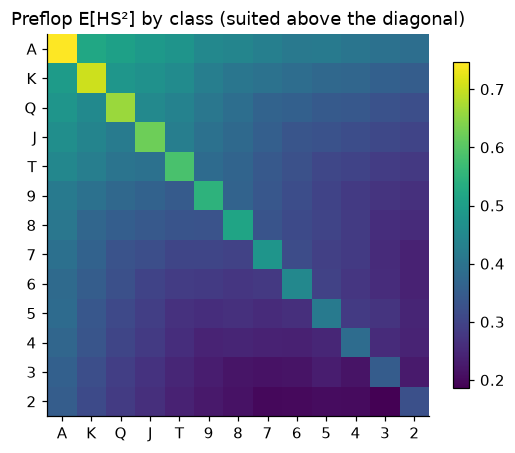

In [5]:
hi_rank = np.maximum(COMBOS[:, 0] // 4, COMBOS[:, 1] // 4)
lo_rank = np.minimum(COMBOS[:, 0] // 4, COMBOS[:, 1] // 4)
suited = COMBOS[:, 0] % 4 == COMBOS[:, 1] % 4
CLASS_KEY = hi_rank * 26 + lo_rank * 2 + suited
CLASSES, CLASS_ID = np.unique(CLASS_KEY, return_inverse=True)

pre_path = CACHE / "preflop_ehs2.npy"
if pre_path.exists():
    PREFLOP_VALUE = np.load(pre_path)
else:
    gen = torch.Generator().manual_seed(1)
    boards = torch.stack([torch.randperm(52, generator=gen)[:5] for _ in range(6000)])
    hs2 = torch.cat([strength(boards[i:i + 200]) ** 2 for i in range(0, len(boards), 200)])
    per_combo = torch.nanmean(hs2, 0).numpy()
    per_class = np.bincount(CLASS_ID, per_combo) / np.bincount(CLASS_ID)
    PREFLOP_VALUE = per_class[CLASS_ID]
    np.save(pre_path, PREFLOP_VALUE)

PREFLOP_BUCKET = to_buckets(torch.from_numpy(PREFLOP_VALUE)).long()

CHEN_FACE = {12: 10, 11: 8, 10: 7, 9: 6}


def chen(a, b):
    ra, rb = sorted([a // 4, b // 4], reverse=True)
    score = CHEN_FACE.get(ra, (ra + 2) / 2)
    if ra == rb:
        score = max(2 * score, 5)
    else:
        gap = ra - rb - 1
        score -= [0, 1, 2, 4, 5][min(gap, 4)]
        if gap <= 1 and ra < 10:
            score += 1
    if a % 4 == b % 4:
        score += 2
    return score


CHEN = np.array([chen(a, b) for a, b in COMBOS])
CHEN_BUCKET = np.digitize(CHEN, [5, 7, 9, 11])


def class_grid(values_per_combo):
    grid = np.zeros((13, 13))
    count = np.zeros((13, 13))
    row = np.where(suited, 12 - hi_rank, 12 - lo_rank)
    col = np.where(suited, 12 - lo_rank, 12 - hi_rank)
    np.add.at(grid, (row, col), values_per_combo)
    np.add.at(count, (row, col), 1)
    return grid, count


grid, count = class_grid(PREFLOP_VALUE)
fig, ax = plt.subplots(figsize=(5.6, 4.8))
im = ax.imshow(grid / count, cmap="viridis")
ax.set_xticks(range(13), RANKS[::-1])
ax.set_yticks(range(13), RANKS[::-1])
ax.grid(False)
ax.set_title("Preflop E[HS²] by class (suited above the diagonal)")
fig.colorbar(im, ax=ax, shrink=0.8)
plt.show()

## 2. Hand histories

### 2.1 Reading PHH files

Each `.phhs` file is one ACPC 2011 heads-up limit match of 3000 hands between two bots. Files are read in archive order (`acpc_manifest.txt`, written by `data/fetch.sh`), so the first 40 are always the paper's sample. Every hand lists the hole cards of **both** players, which is what makes the censoring experiments possible: we know the truth even for folded hands.

Seats rotate between hands; `p2` is the button (small blind), acts first preflop and last after the flop. Bets are 10 chips preflop and on the flop, 20 on the turn and river, with at most four bets per street.

For every action we record the public context
$X=(t,\ \text{facing},\ \text{bets so far},\ \text{button})$,
which fixes the legal set $\mathcal{L}(x)$: check/bet when not facing a bet, fold/call/raise when facing one, fold/call at the cap. We also record the pot and the amount to call, which the decision layer needs. $R_h=1$ when nobody folds.

In [6]:
SB, BB = 2, 1
BET = [10, 10, 20, 20]
NX = 4 * 2 * 5 * 2
STREETS = ["preflop", "flop", "turn", "river"]


def context(street, facing, bets, button):
    return ((street * 2 + facing) * 5 + bets) * 2 + button


def decode(x):
    return x // 20, (x // 10) % 2, (x // 2) % 5, x % 2


LEGAL = torch.tensor([[decode(x)[1] == 1, True, decode(x)[2] < 4] for x in range(NX)])


def read_phhs(path):
    hands, cur = [], None
    for line in open(path):
        line = line.strip()
        if line.startswith("["):
            if cur:
                hands.append(cur)
            cur = {}
        elif " = " in line:
            key, value = line.split(" = ", 1)
            cur[key] = ast.literal_eval(value.replace("true", "True").replace("false", "False"))
    if cur:
        hands.append(cur)
    return hands


def parse_hand(raw):
    hole, board, events = {}, [], []
    street, bets, level, pot, folded = 0, 1, {BB: 1.0, SB: 0.5}, 15.0, False
    for token in raw["actions"]:
        f = token.split()
        if f[0] == "d":
            if f[1] == "dh":
                hole[int(f[2][1])] = parse_cards(f[3])
            else:
                street, bets, level = street + 1, 0, {BB: 0.0, SB: 0.0}
                board += parse_cards(f[2])
                events.append(("deal", street, 0, -1, -1, pot, 0.0))
            continue
        if f[1] not in ("f", "cc", "cbr"):
            continue
        seat = int(f[0][1])
        facing = int(level[seat] < bets)
        act = ("f", "cc", "cbr").index(f[1])
        to_call = (bets - level[seat]) * BET[street]
        x = context(street, facing, bets, int(seat == SB))
        assert LEGAL[x, act]
        events.append(("act", street, seat, act, x, pot, to_call))
        if act == 0:
            folded = True
        elif act == 1:
            pot, level[seat] = pot + to_call, bets
        else:
            bets += 1
            pot, level[seat] = pot + (bets - level[seat]) * BET[street], bets
    return {"players": raw["players"], "hole": hole, "board": board, "events": events,
            "revealed": not folded, "results": raw["_results"]}


PAPER_MATCHES = 40
manifest = DATA / "acpc_manifest.txt"
if manifest.exists():
    MATCH_FILES = [DATA / line.strip() for line in open(manifest) if (DATA / line.strip()).exists()]
else:
    MATCH_FILES = sorted(DATA.rglob("*acpc_2011_2p_limit*/**/*.phhs"))
assert len(MATCH_FILES) >= max(MODEL_MATCHES, PAPER_MATCHES), "Not enough ACPC matches: run `devbox run data` first."
MATCH_FILES = MATCH_FILES[:max(MODEL_MATCHES, PAPER_MATCHES)]
t0 = time.time()
HANDS = []
for m, path in enumerate(MATCH_FILES):
    for i, raw in enumerate(read_phhs(path)):
        hand = parse_hand(raw)
        hand["match"], hand["index"] = m, i
        HANDS.append(hand)
assert all(next(e for e in h["events"] if e[0] == "act")[2] == SB for h in HANDS)
print(f"{len(HANDS):,} hands from {len(MATCH_FILES)} matches in {time.time() - t0:.1f}s")
example = HANDS[2]
print(example["players"], [card_str(c) for c in example["hole"][1]], [card_str(c) for c in example["hole"][2]],
      [card_str(c) for c in example["board"]])
for e in example["events"]:
    print(e[0], STREETS[e[1]], "seat", e[2], ACTIONS[e[3]] if e[3] >= 0 else "", "x =", e[4], "pot", e[5])

120,000 hands from 40 matches in 15.6s
['Patience', 'Calvin'] ['6h', 'Qd'] ['3h', '2h'] []
act preflop seat 2 f x = 13 pot 15.0


## 3. Hidden cards and the showdown-only error

### 3.1 Table 2: the first decision of the small blind

Proposition 2 says that learning only from hands that reach showdown estimates $P(A=a\mid s,x,R=1)$ instead of $\theta_{x,s}(a)$. We measure this directly on the paper's 40-match sample (the first 40 matches of the archive, 120,000 hands): the **oracle** uses every hand (all cards are known in ACPC), the **showdown-only** estimator uses only hands with $R=1$. Buckets are the Chen-score groups used in the paper's preliminary table.

     Chen bucket | oracle f      c      r |       n | showdown f      c      r
 0 (weakest, <5) |    0.246  0.288  0.467 |  71,202 |      0.000  0.420  0.580
         1 (5-7) |    0.037  0.286  0.677 |  28,044 |      0.000  0.324  0.676
         2 (7-9) |    0.027  0.293  0.680 |  12,664 |      0.000  0.321  0.679
        3 (9-11) |    0.021  0.278  0.700 |   5,211 |      0.000  0.305  0.695
   4 (strongest) |    0.010  0.222  0.768 |   2,879 |      0.000  0.251  0.749


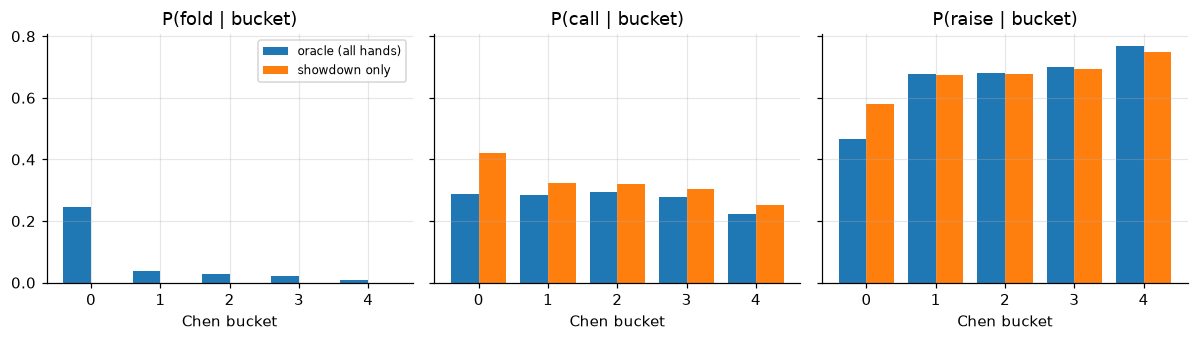

In [7]:
PAPER_HANDS = [h for h in HANDS if h["match"] < PAPER_MATCHES]
first = [next(e for e in h["events"] if e[0] == "act") for h in PAPER_HANDS]
sb_bucket = np.array([CHEN_BUCKET[COMBO_ID[h["hole"][SB][0], h["hole"][SB][1]]] for h in PAPER_HANDS])
sb_action = np.array([e[3] for e in first])
revealed = np.array([h["revealed"] for h in PAPER_HANDS])

oracle = np.zeros((5, 3))
shown = np.zeros((5, 3))
np.add.at(oracle, (sb_bucket, sb_action), 1)
np.add.at(shown, (sb_bucket[revealed], sb_action[revealed]), 1)
labels = ["0 (weakest, <5)", "1 (5-7)", "2 (7-9)", "3 (9-11)", "4 (strongest)"]
print(f"{'Chen bucket':>16} | {'oracle f':>8} {'c':>6} {'r':>6} | {'n':>7} | {'showdown f':>10} {'c':>6} {'r':>6}")
for s in range(5):
    o = oracle[s] / oracle[s].sum()
    d = shown[s] / shown[s].sum()
    print(f"{labels[s]:>16} | {o[0]:8.3f} {o[1]:6.3f} {o[2]:6.3f} | {int(oracle[s].sum()):7,d} | {d[0]:10.3f} {d[1]:6.3f} {d[2]:6.3f}")

fig, axes = plt.subplots(1, 3, figsize=(11, 3.2), sharey=True)
for a, ax in enumerate(axes):
    ax.bar(np.arange(5) - 0.2, oracle[:, a] / oracle.sum(1), 0.4, label="oracle (all hands)")
    ax.bar(np.arange(5) + 0.2, shown[:, a] / shown.sum(1), 0.4, label="showdown only")
    ax.set_title(f"P({['fold', 'call', 'raise'][a]} | bucket)")
    ax.set_xlabel("Chen bucket")
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

### 3.2 Proposition 2, checked numerically

With $\kappa(a,s)=P(R=1\mid A=a, S=s)$, the showdown-only estimate should equal
$\tilde\theta_s(a)=\theta_s(a)\kappa(a,s)/\sum_{a'}\theta_s(a')\kappa(a',s)$.
We estimate $\theta$ and $\kappa$ from all hands and compare the formula with the direct showdown-only frequencies. The tilt of the strength distribution, $P(S=s\mid R=1)\propto P(S=s)P(R=1\mid S=s)$, is checked the same way.

In [8]:
theta_o = oracle / oracle.sum(1, keepdims=True)
kappa = np.divide(shown, oracle, out=np.zeros_like(shown), where=oracle > 0)
predicted = theta_o * kappa / (theta_o * kappa).sum(1, keepdims=True)
direct = shown / shown.sum(1, keepdims=True)
print("kappa(a, s) = P(showdown | action, bucket):")
print(np.round(kappa, 3))
print("max |formula - direct showdown-only frequency| =", np.abs(predicted - direct).max())

p_s = oracle.sum(1) / oracle.sum()
p_r_s = shown.sum(1) / oracle.sum(1)
tilt = p_s * p_r_s / (p_s * p_r_s).sum()
print("\nP(S=s):           ", np.round(p_s, 3))
print("P(S=s | R=1):     ", np.round(shown.sum(1) / shown.sum(), 3))
print("formula (tilt):   ", np.round(tilt, 3))

kappa(a, s) = P(showdown | action, bucket):
[[0.    0.59  0.502]
 [0.    0.645 0.568]
 [0.    0.646 0.587]
 [0.    0.676 0.612]
 [0.    0.72  0.621]]
max |formula - direct showdown-only frequency| = 1.1102230246251565e-16

P(S=s):            [0.593 0.234 0.106 0.043 0.024]
P(S=s | R=1):      [0.503 0.279 0.13  0.056 0.032]
formula (tilt):    [0.503 0.279 0.13  0.056 0.032]


### 3.3 Descriptive statistics

How often hands reach each street, and how strongly the showdown sample over-represents strong holdings.

In [9]:
n_board = np.array([len(h["board"]) for h in PAPER_HANDS])
print(f"reach showdown: {revealed.mean():.1%}")
print(f"see a flop: {(n_board >= 3).mean():.1%}, a turn: {(n_board >= 4).mean():.1%}, a river: {(n_board >= 5).mean():.1%}")
print(f"weakest Chen bucket among all hands: {(sb_bucket == 0).mean():.1%}, among showdown hands: {(sb_bucket[revealed] == 0).mean():.1%}")

reach showdown: 47.7%
see a flop: 78.5%, a turn: 64.4%, a river: 54.4%
weakest Chen bucket among all hands: 59.3%, among showdown hands: 50.3%


## 4. The model and exact updating within a hand

### 4.1 Strength buckets for every possible board

$S_t=\phi_t(c,B_t)$ depends only on the board, and up to a relabelling of suits there are only 1,755 flops, 16,432 turns and 134,459 rivers. We compute the buckets of all 1326 pairs on **every** canonical board once: $\mathbf{E}[\mathrm{HS}^2]$ buckets on the flop (from `FLOP_ROLLOUTS` completions) and the turn (exact), $\mathrm{HS}$ buckets on the river. The table takes about six minutes the first time and about 200 MB on disk.

After that, a hand only stores which canonical board it has on each street and the suit permutation that maps it there; `BoardBuckets` looks up `BK[h, t]` (the buckets of all pairs) or `BK[h, t, c]` (one pair) on demand. Adding more hands then costs nothing for features, which is what lets the model scale to many matches.

In [10]:
def canonical_code(boards):
    canon, perm = canonical(boards)
    return (canon * BOARD_CODE[: boards.shape[1]]).sum(-1), perm


def all_canonical_boards(k, chunk=250_000):
    combos = torch.tensor(list(itertools.combinations(range(52), k)))
    codes = torch.unique(torch.cat([canonical_code(combos[i:i + chunk])[0] for i in range(0, len(combos), chunk)]))
    boards = torch.stack([(codes // 52 ** j) % 52 for j in range(k)], 1)
    return codes, boards


table_path = CACHE / f"board_buckets_k{K}_f{FLOP_ROLLOUTS}.npz"
if table_path.exists():
    saved = np.load(table_path)
    BOARD_TABLES = {s: (torch.from_numpy(saved[f"codes{s}"]), torch.from_numpy(saved[f"table{s}"])) for s in (1, 2, 3)}
else:
    t0 = time.time()
    gen = torch.Generator().manual_seed(2)
    BOARD_TABLES = {}
    for street, n_cards, batch in ((1, 3, 16), (2, 4, 16), (3, 5, 96)):
        codes, boards = all_canonical_boards(n_cards)
        table = torch.empty(len(boards), NC, dtype=torch.int8)
        for i in range(0, len(boards), batch):
            b = boards[i:i + batch]
            value = expected_hs2(b, gen=gen) if n_cards == 3 else exact_turn_hs2(b) if n_cards == 4 else strength(b)
            table[i:i + batch] = to_buckets(value)
        BOARD_TABLES[street] = (codes, table)
        print(f"{STREETS[street]}: {len(boards):,} canonical boards, {time.time() - t0:.0f}s")
    np.savez(table_path, **{f"codes{s}": BOARD_TABLES[s][0].numpy() for s in (1, 2, 3)},
             **{f"table{s}": BOARD_TABLES[s][1].numpy() for s in (1, 2, 3)})


class BoardBuckets:
    def __init__(self, hands, tables, preflop_only=False):
        self.tables, self.preflop_only = tables, preflop_only
        self.ids = torch.full((len(hands), 4), -1, dtype=torch.long)
        self.perm = torch.zeros((len(hands), 4), dtype=torch.long)
        for street, n_cards in ((1, 3), (2, 4), (3, 5)):
            rows = torch.tensor([i for i, h in enumerate(hands) if len(h["board"]) >= n_cards], dtype=torch.long)
            if len(rows) == 0:
                continue
            code, perm = canonical_code(torch.tensor([hands[i]["board"][:n_cards] for i in rows.tolist()]))
            codes = tables[street][0]
            idx = torch.searchsorted(codes, code)
            assert (codes[idx] == code).all()
            self.ids[rows, street], self.perm[rows, street] = idx, perm

    def preflop_view(self):
        view = BoardBuckets([], self.tables, preflop_only=True)
        view.ids, view.perm = self.ids, self.perm
        return view

    def __getitem__(self, key):
        h, t = torch.as_tensor(key[0]), torch.as_tensor(key[1])
        scalar = h.dim() == 0
        h = h.reshape(-1)
        t = t.reshape(-1).expand_as(h) if t.numel() == 1 else t.reshape(-1)
        c = torch.as_tensor(key[2]).reshape(-1).expand_as(h) if len(key) == 3 else None
        out = torch.empty((len(h),) if c is not None else (len(h), NC), dtype=torch.long)
        for s in range(4):
            m = t == s
            if not m.any():
                continue
            if s == 0 or self.preflop_only:
                out[m] = PREFLOP_BUCKET[c[m]] if c is not None else PREFLOP_BUCKET.expand(int(m.sum()), NC)
                continue
            ids, perm = self.ids[h[m], s], self.perm[h[m], s]
            table = self.tables[s][1]
            if c is not None:
                vals = table[ids.clamp(min=0), COMBO_PERM[perm, c[m]]].long()
                out[m] = torch.where(ids >= 0, vals, -1)
            else:
                vals = table[ids.clamp(min=0)].long().gather(1, COMBO_PERM[perm])
                out[m] = torch.where((ids >= 0)[:, None], vals, -1)
        return out[0] if scalar else out


MODEL_HANDS = [h for h in HANDS if h["match"] < MODEL_MATCHES]
H = len(MODEL_HANDS)
BK_HULHE = BoardBuckets(MODEL_HANDS, BOARD_TABLES)
print(f"{H:,} hands from {MODEL_MATCHES} matches mapped to canonical boards")

i0 = next(i for i, h in enumerate(MODEL_HANDS) if len(h["board"]) == 5)
h0 = MODEL_HANDS[i0]
river = BK_HULHE[i0, 3]
direct = to_buckets(strength(torch.tensor([h0["board"]])))[0].long()
assert torch.equal(river, direct)
print("board:", " ".join(card_str(c) for c in h0["board"]), "(table lookup matches direct computation)")
print("pairs per river bucket (equal mass up to ties):", torch.bincount(river[river >= 0]).tolist())
for seat in (1, 2):
    pair = h0["hole"][seat]
    print(f"seat {seat} holds {card_str(pair[0])}{card_str(pair[1])}: buckets by street",
          [int(BK_HULHE[i0, t, COMBO_ID[pair[0], pair[1]]]) for t in range(4)])

120,000 hands from 40 matches mapped to canonical boards
board: 6d Jd 2c 3c Jc (table lookup matches direct computation)
pairs per river bucket (equal mass up to ties): [135, 135, 135, 144, 129, 135, 132, 136]
seat 1 holds 8s7s: buckets by street [4, 1, 0, 0]
seat 2 holds Ac5h: buckets by street [5, 2, 3, 3]


### 4.2 Records: one opponent, one observer

The model is written from the observer's side. Every hand gives two **records**, one per seat: the player in that seat is the opponent $\mathsf{P}$, the other is the observer $\mathsf{O}$. A **session** is one opponent's sequence of hands within a match, the time axis of the style chain $Z_h$.

A record stores what the model needs:
- the opponent's actions $(t, x, a)$ (the observer's actions only enter through $x$);
- the visible cards with the street they appear on, for card removal $\mathcal{C}(o_h, B_{h,t})$;
- $R_h$ and, for evaluation only, the opponent's true pair.

The same container is reused for Kuhn and Leduc poker later: only the card space, buckets and contexts change. Each session is split in time into training (first 60% of its hands), validation (next 10%) and test (last 30%); Section 5.2 explains the protocol.

In [11]:
class Dataset:
    def __init__(self, BK, has, vis_street, records, legal, k, split=(0.6, 0.7)):
        self.BK, self.has, self.legal, self.K = BK, has, legal, k
        self.nc, self.NX = has.shape[0], legal.shape[0]
        self.vis_street = torch.tensor(vis_street)
        self.hand = torch.tensor([r["hand"] for r in records])
        self.true = torch.tensor([r["true"] for r in records])
        self.revealed = torch.tensor([r["revealed"] for r in records])
        self.session = torch.tensor([r["session"] for r in records])
        self.reached = torch.tensor([r["reached"] for r in records])
        self.vis = torch.tensor([r["vis"] for r in records])
        ev = [(i, t, x, a) for i, r in enumerate(records) for (t, x, a) in r["acts"]]
        ev = torch.tensor(ev, dtype=torch.long).reshape(-1, 4)
        self.ev_rec, self.ev_t, self.ev_x, self.ev_a = ev.unbind(1)
        self.ptr = torch.zeros(len(records) + 1, dtype=torch.long)
        self.ptr[1:] = torch.cumsum(torch.bincount(self.ev_rec, minlength=len(records)), 0)
        sizes = torch.bincount(self.session)
        start = torch.cumsum(sizes, 0) - sizes
        pos = torch.arange(len(records)) - start[self.session]
        frac = pos.double() / sizes[self.session].double()
        self.part = (frac >= split[0]).long() + (frac >= split[1]).long()
        self.train, self.val, self.test = self.part == 0, self.part == 1, self.part == 2
        self.cache = {}
        self.records = records

    def __len__(self):
        return len(self.hand)


def hulhe_records(hands):
    records, sessions = [], {}
    by_match = {}
    for hh, h in enumerate(hands):
        by_match.setdefault(h["match"], []).append(hh)
    for m, idx in by_match.items():
        for name in sorted(hands[idx[0]]["players"]):
            sid = sessions.setdefault((m, name), len(sessions))
            for hh in idx:
                h = hands[hh]
                opp = h["players"].index(name) + 1
                obs = 3 - opp
                board = h["board"] + [-1] * (5 - len(h["board"]))
                records.append({
                    "hand": hh, "session": sid, "opp": opp, "name": name,
                    "true": int(COMBO_ID[h["hole"][opp][0], h["hole"][opp][1]]),
                    "revealed": h["revealed"],
                    "reached": max(0, len(h["board"]) - 2),
                    "vis": h["hole"][obs] + board,
                    "acts": [(e[1], e[4], e[3]) for e in h["events"] if e[0] == "act" and e[2] == opp],
                })
    return records, {v: k for k, v in sessions.items()}


t0 = time.time()
REC, SESSIONS = hulhe_records(MODEL_HANDS)
D = Dataset(BK_HULHE, COMBO_HAS_T, [0, 0, 1, 1, 1, 2, 3], REC, LEGAL, K)
print(f"{len(D):,} records, {len(D.ev_rec):,} opponent actions, {len(SESSIONS)} sessions, "
      f"{int(D.train.sum()):,} train / {int(D.val.sum()):,} validation / {int(D.test.sum()):,} test, built in {time.time() - t0:.1f}s")

240,000 records, 865,993 opponent actions, 80 sessions, 144,000 train / 24,000 validation / 72,000 test, built in 1.3s


### 4.3 The likelihood of a record and the exact update (eq. 7)

For a style $z$ and parameters $\theta$, the probability of the hidden pair being $c$ and of the opponent's actions is

$$
f(c\mid z)\ =\ \frac{1}{|\mathcal{C}(o_h,\varnothing)|}\,\mathbf{1}\big[c\in\mathcal{C}(o_h,B_h)\big]\prod_{(t,j)}\theta_{z,\,x_{t,j},\,\phi_t(c,B_t)}\big(a_{t,j}\big).
$$

The probability of the board given $c$ is the same for every consistent pair, so it is left out. `loglik` evaluates $\log f(c\mid z)$ for all 1326 pairs and all styles at once: each action contributes the row $\log\theta_{z,x,\cdot}(a)$, looked up at each pair's bucket on that street, and the contributions of a record are summed. Restricting to actions up to street $\tau$ (and to the cards visible by then) gives the conditional PMF after street $\tau$; normalizing over $c$ is Bayes' rule. `last_only` keeps a single action per record, which is the one-action model of Terry and Mihok. `upto` keeps only each record's first few actions, so that a decision is judged only on what had happened before it.

In [12]:
def valid_at(D, recs, tau=None):
    v = D.vis[recs]
    show = v >= 0
    if tau is not None:
        limit = tau.reshape(-1, 1) if torch.is_tensor(tau) else torch.tensor(tau)
        show = show & (D.vis_street[None, :] <= limit)
    conflict = (D.has.T[v.clamp(min=0)] & show[..., None]).any(1)
    return ~conflict


def record_events(D, recs, tau=None, last_only=False, upto=None):
    starts, ends = D.ptr[recs], D.ptr[recs + 1]
    counts = ends - starts
    loc = torch.repeat_interleave(torch.arange(len(recs)), counts)
    offset = torch.arange(int(counts.sum())) - torch.repeat_interleave(torch.cumsum(counts, 0) - counts, counts)
    ev = torch.repeat_interleave(starts, counts) + offset
    if upto is not None:
        keep = offset < upto[loc]
        ev, loc = ev[keep], loc[keep]
    if tau is not None:
        keep = D.ev_t[ev] <= (tau[loc] if torch.is_tensor(tau) else tau)
        ev, loc = ev[keep], loc[keep]
    if last_only and len(ev):
        last = torch.full((len(recs),), -1, dtype=torch.long).scatter_reduce(0, loc, ev, "amax")
        keep = ev == last[loc]
        ev, loc = ev[keep], loc[keep]
    return ev, loc


def cached(D, key, build):
    if key not in D.cache:
        D.cache[key] = build()
    return D.cache[key]


def event_buckets(D, ev, BK=None):
    if BK is not None and BK is not D.BK:
        return BK[D.hand[D.ev_rec[ev]], D.ev_t[ev]]

    def build():
        out = torch.empty(len(D.ev_rec), D.nc, dtype=torch.int8)
        for i in range(0, len(D.ev_rec), 20_000):
            e = torch.arange(i, min(i + 20_000, len(D.ev_rec)))
            out[e] = D.BK[D.hand[D.ev_rec[e]], D.ev_t[e]].to(torch.int8)
        return out
    return cached(D, "event_buckets", build)[ev].long()


def final_valid(D, recs):
    def build():
        return torch.cat([valid_at(D, torch.arange(i, min(i + 20_000, len(D)))) for i in range(0, len(D), 20_000)])
    return cached(D, "valid", build)[recs]


def card_prior(D, recs):
    def build():
        return torch.cat([-torch.log(valid_at(D, torch.arange(i, min(i + 20_000, len(D))), 0).sum(-1).float())
                          for i in range(0, len(D), 20_000)])
    return cached(D, "prior", build)[recs]


def loglik(D, logt, recs, tau=None, last_only=False, BK=None, upto=None):
    ev, loc = record_events(D, recs, tau, last_only, upto)
    b = event_buckets(D, ev, BK)
    lt = logt[:, D.ev_x[ev], :, D.ev_a[ev]].float()
    mz = logt.shape[0]
    g = lt.gather(2, b.clamp(min=0)[:, None, :].expand(-1, mz, -1))
    out = torch.zeros(len(recs), mz, D.nc, dtype=torch.float32).index_add_(0, loc, g)
    valid = final_valid(D, recs) if tau is None else valid_at(D, recs, tau)
    out = torch.where(valid[:, None, :], out, torch.tensor(-torch.inf))
    return out + card_prior(D, recs)[:, None, None], ev, loc, b


def loglik_true(D, logt, recs, BK=None):
    ev, loc = record_events(D, recs)
    rec = D.ev_rec[ev]
    s = (D.BK if BK is None else BK)[D.hand[rec], D.ev_t[ev], D.true[rec]]
    lt = logt[:, D.ev_x[ev], s, D.ev_a[ev]].float()
    out = torch.zeros(len(recs), logt.shape[0], dtype=torch.float32).index_add_(0, loc, lt.T)
    return out + card_prior(D, recs)[:, None], ev, loc, s


def safe_log(theta):
    return torch.log(theta.clamp(min=1e-300))


def counts_from_truth(D, mask):
    sel = mask[D.ev_rec]
    rec = D.ev_rec[sel]
    s = D.BK[D.hand[rec], D.ev_t[sel], D.true[rec]]
    n = torch.zeros(D.NX, D.K, 3)
    n.index_put_((D.ev_x[sel], s, D.ev_a[sel]), torch.ones(int(sel.sum())), accumulate=True)
    return n


def context_reference(D, mask):
    sel = mask[D.ev_rec]
    n = torch.zeros(D.NX, 3)
    n.index_put_((D.ev_x[sel], D.ev_a[sel]), torch.ones(int(sel.sum())), accumulate=True)
    n = n + D.legal.double()
    m = n * D.legal / (n * D.legal).sum(1, keepdim=True)
    return m[:, None, :].expand(D.NX, D.K, 3).clone()


def posterior_mean(counts, prior):
    a = counts + prior
    return a / a.sum(-1, keepdim=True)


REF = context_reference(D, D.train)
ORACLE_ALL = posterior_mean(counts_from_truth(D, torch.ones(len(D), dtype=torch.bool)), 2.0 * REF)

### 4.4 Example: reading one hand street by street

We take $\theta$ estimated from all cards (the oracle) and follow the conditional PMF of the opponent's pair through one hand. Each panel sums the probability of the pairs in each of the 169 classes (suited above the diagonal); the red square is the opponent's actual hand.

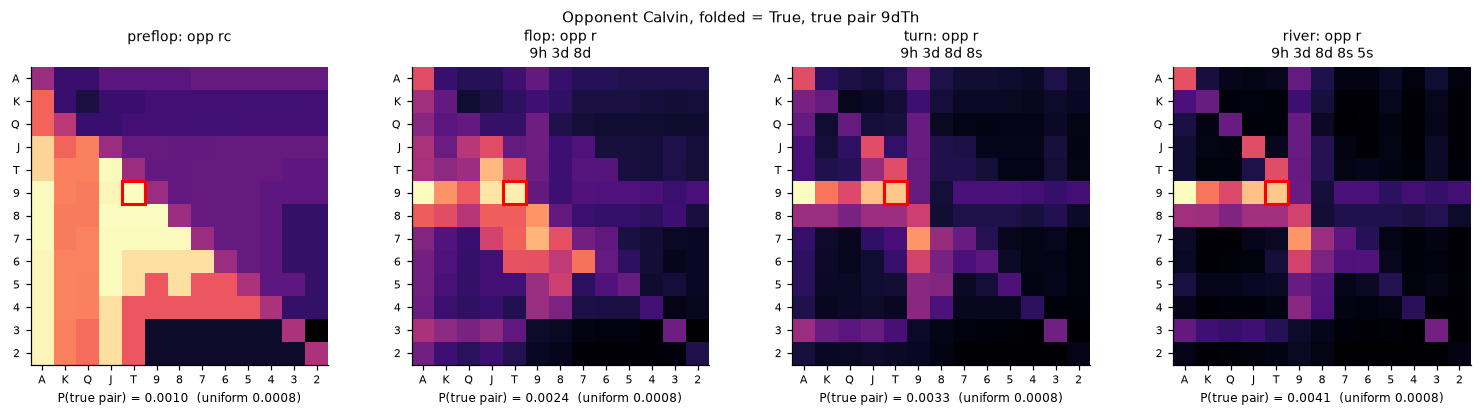

In [13]:
def class_mass(p):
    grid, _ = class_grid(p)
    return grid


def pick_example(D, min_actions=5):
    for r in range(len(D)):
        rec = D.records[r]
        if D.test[r] and D.reached[r] == 3 and len(rec["acts"]) >= min_actions and not D.revealed[r]:
            return r
    return int(torch.nonzero(D.test & (D.reached == 3))[0])


EX = pick_example(D)
ex = D.records[EX]
ex_hand = MODEL_HANDS[ex["hand"]]
logt_oracle = safe_log(ORACLE_ALL)[None]
fig, axes = plt.subplots(1, 4, figsize=(14, 3.6))
for tau, ax in enumerate(axes):
    L, *_ = loglik(D, logt_oracle, torch.tensor([EX]), tau=tau)
    p = torch.softmax(L[0, 0], -1).numpy()
    ax.imshow(class_mass(p), cmap="magma")
    tc = COMBOS[ex["true"]]
    r_, c_ = (12 - max(tc // 4), 12 - min(tc // 4)) if tc[0] % 4 == tc[1] % 4 else (12 - min(tc // 4), 12 - max(tc // 4))
    ax.add_patch(plt.Rectangle((c_ - 0.5, r_ - 0.5), 1, 1, fill=False, ec="red", lw=2))
    acts = "".join(ACTIONS[a] for (t, x, a) in ex["acts"] if t == tau)
    board = " ".join(card_str(c) for c in ex_hand["board"][: [0, 3, 4, 5][tau]])
    ax.set_title(f"{STREETS[tau]}: opp {acts or '-'}\n{board}", fontsize=9)
    ax.set_xticks(range(13), RANKS[::-1], fontsize=7)
    ax.set_yticks(range(13), RANKS[::-1], fontsize=7)
    ax.grid(False)
    p_true = p[ex["true"]]
    ax.set_xlabel(f"P(true pair) = {p_true:.4f}  (uniform {1 / 1225:.4f})", fontsize=8)
plt.suptitle(f"Opponent {ex['name']}, folded = {not ex['revealed']}, true pair "
             f"{card_str(COMBOS[ex['true']][0])}{card_str(COMBOS[ex['true']][1])}", fontsize=10)
plt.tight_layout()
plt.show()

## 5. Learning

### 5.1 The expected-count iteration

The parameters are random variables with joint PDFs $\propto\prod_a\vartheta(a)^{\lambda_z m_{x,s}(a)-1}$ (eq. 6). The reference $\mathbf{m}_{x,s}$ is the population's action frequency in context $x$, which is observable without any cards. The reference ignores hand strength, so its weight must stay modest: a strong prior flattens exactly the strength dependence that folded hands are read through. We use $\lambda_1=20$ (enough to tie style 1 to the reference and keep the styles from swapping labels) and $\lambda=2$ for the other styles, which may move away freely. Section 6.3 compares this with a strong prior ($\lambda=200$).

Each iteration has two steps:

1. **Expected counts.** For each record and style, the probability of its observations $e_h(z)$ (summing over hidden pairs when $R_h=0$), and the conditional PMF of the pair, turned into the conditional PMF of each action's bucket. A forward and a backward recursion over each session's Markov chain give $\gamma_h(z)=P(Z_h=z\mid\text{all hands})$ and the expected number of style changes. Expected counts $\bar N_{z,x,s,a}$ follow from the total expectation theorem (eq. 9).
2. **New parameters.** The conditional joint PDF of $\theta_{z,x,s}$ keeps the same form with exponents raised by $\bar N$. We keep its parameters `alpha` (used later for certificates and intervals) and take its mean as the point value. $\varepsilon$ is updated from the expected number of changes with a prior concentrated near small values.

A folded hand spreads its one count over buckets according to the conditional PMF of the pair. This is the step that removes the showdown-only error.

Iterations stop when the log-probability of the data improves by less than one part in $10^5$. Fitted models are cached in `data/cache/models/` (delete the folder to refit).

In [14]:
def e_step(D, logt, recs, chunk=2000, BK=None):
    mz = logt.shape[0]
    loge = torch.empty(len(recs), mz)
    marg = torch.zeros(len(D.ev_rec), mz, D.K, dtype=torch.float32)
    rev = D.revealed[recs]
    shown, hidden = torch.nonzero(rev).squeeze(1), torch.nonzero(~rev).squeeze(1)
    for i in range(0, len(shown), 20_000):
        pos = shown[i:i + 20_000]
        L, ev, loc, s = loglik_true(D, logt, recs[pos], BK=BK)
        loge[pos] = L.double()
        marg[ev] = torch.nn.functional.one_hot(s.clamp(min=0), D.K).float()[:, None, :].expand(-1, mz, -1)
    for i in range(0, len(hidden), chunk):
        pos = hidden[i:i + chunk]
        L, ev, loc, b = loglik(D, logt, recs[pos], BK=BK)
        lse = torch.logsumexp(L, -1)
        loge[pos] = lse.double()
        post = torch.exp(L - lse[..., None])
        m = torch.zeros(len(ev), mz, D.K + 1, dtype=torch.float32)
        m.scatter_add_(2, (b + 1)[:, None, :].expand(-1, mz, -1), post[loc])
        marg[ev] = m[:, :, 1:]
    return loge, marg


def session_grid(D, recs):
    sess = D.session[recs]
    ids, sizes = torch.unique_consecutive(sess, return_counts=True)
    grid = torch.full((len(ids), int(sizes.max())), -1, dtype=torch.long)
    start = 0
    for i, n in enumerate(sizes.tolist()):
        grid[i, :n] = torch.arange(start, start + n)
        start += n
    return grid


def forward_backward(loge, grid, log_rho, log_G):
    S, L = grid.shape
    mz = loge.shape[1]
    real = grid >= 0
    le = torch.where(real[..., None], loge[grid.clamp(min=0)], torch.zeros(()))
    la = torch.empty(S, L, mz)
    la[:, 0] = log_rho + le[:, 0]
    for t in range(1, L):
        la[:, t] = le[:, t] + torch.logsumexp(la[:, t - 1, :, None] + log_G, 1)
    lb = torch.zeros(S, L, mz)
    for t in range(L - 2, -1, -1):
        lb[:, t] = torch.logsumexp(log_G + (le[:, t + 1] + lb[:, t + 1])[:, None, :], 2)
    logz = torch.logsumexp(la[:, -1], -1)
    gamma_grid = torch.softmax(la + lb, -1)
    gamma = torch.empty(len(loge), mz)
    gamma[grid[real]] = gamma_grid[real]
    xi = torch.exp(la[:, :-1, :, None] + log_G + (le[:, 1:] + lb[:, 1:])[:, :, None, :] - logz[:, None, None, None])
    xi = (xi * real[:, 1:, None, None]).sum((0, 1))
    return gamma, xi, float(logz.sum())


def filter_predictive(loge, grid, log_rho, log_G):
    S, L = grid.shape
    real = grid >= 0
    le = torch.where(real[..., None], loge[grid.clamp(min=0)], torch.zeros(()))
    pred = torch.empty(S, L, loge.shape[1])
    filt = torch.empty_like(pred)
    pred[:, 0] = log_rho - torch.logsumexp(log_rho, -1)
    for t in range(L):
        if t:
            pred[:, t] = torch.logsumexp(filt[:, t - 1, :, None] + log_G, 1)
        f = pred[:, t] + le[:, t]
        filt[:, t] = f - torch.logsumexp(f, -1, keepdim=True)
    out_pred = torch.empty(len(loge), loge.shape[1])
    out_filt = torch.empty_like(out_pred)
    out_pred[grid[real]] = pred[real]
    out_filt[grid[real]] = filt[real]
    return out_pred, out_filt


def transition(eps, mz):
    if mz == 1:
        return torch.ones(1, 1)
    return torch.full((mz, mz), eps / (mz - 1)) + torch.eye(mz) * (1 - eps - eps / (mz - 1))


def style_init(base, mz):
    styles = [base]
    tilts = [torch.tensor([1.0, 1.0, 2.5]), torch.tensor([1.0, 2.5, 0.4]), torch.tensor([0.5, 1.0, 1.5])]
    for z in range(1, mz):
        t = base * tilts[(z - 1) % 3]
        styles.append(t / t.sum(-1, keepdim=True))
    return torch.stack(styles)


MODEL_CACHE = CACHE / "models"
MODEL_CACHE.mkdir(exist_ok=True)


def memo(name, build):
    path = MODEL_CACHE / f"m{MODEL_MATCHES}_k{K}_{name}.pt"
    if path.exists():
        return torch.load(path, weights_only=False)
    out = build()
    torch.save(out, path)
    return out


def fit(D, recs, mz=1, lam=(20.0, 2.0), iters=40, eps_prior=(1.0, 300.0), BK=None, ref=None, init=None, verbose=True, tol=1e-5):
    ref = REF if ref is None else ref
    lams = torch.tensor([lam[0]] + [lam[-1]] * (mz - 1))
    prior = lams[:, None, None, None] * ref[None]
    theta = style_init(ref if init is None else init, mz)
    eps, rho = 0.01, torch.full((mz,), 1.0 / mz)
    grid = session_grid(D, recs)
    sub = torch.zeros(len(D), dtype=torch.bool)
    sub[recs] = True
    history = []
    for it in range(iters):
        t0 = time.time()
        loge, marg = e_step(D, safe_log(theta), recs, BK=BK)
        if mz == 1:
            gamma, xi, ll = torch.ones(len(recs), 1), torch.zeros(1, 1), float(loge.sum())
        else:
            gamma, xi, ll = forward_backward(loge, grid, torch.log(rho), torch.log(transition(eps, mz)))
        history.append(ll)
        converged = len(history) > 1 and abs(history[-1] - history[-2]) <= tol * abs(history[-1])
        full_gamma = torch.zeros(len(D), mz)
        full_gamma[recs] = gamma
        sel = sub[D.ev_rec]
        w = full_gamma[D.ev_rec[sel]][:, :, None] * marg[sel].double()
        flat = (D.ev_x[sel] * 3 + D.ev_a[sel])
        counts = torch.zeros(mz, D.NX * 3, D.K).index_add_(1, flat, w.permute(1, 0, 2))
        counts = counts.reshape(mz, D.NX, 3, D.K).permute(0, 1, 3, 2)
        alpha = prior + counts
        theta = alpha / alpha.sum(-1, keepdim=True)
        if mz > 1:
            switches = xi.sum() - xi.diagonal().sum()
            eps = float((switches + eps_prior[0] - 1) / (xi.sum() + sum(eps_prior) - 2))
            rho = gamma[grid[:, 0]].mean(0) + 1e-3
            rho = rho / rho.sum()
        if verbose:
            print(f"iteration {it + 1:2d}: log P(data) = {ll:,.1f}   eps = {eps:.4f}   ({time.time() - t0:.1f}s)")
        if converged:
            break
    return {"theta": theta, "alpha": alpha, "counts": counts, "eps": eps, "rho": rho,
            "gamma": gamma, "history": history, "M": mz, "BK": None}

### 5.2 Protocol and model selection

Every session is split in time: the first 60% of its hands are for **training**, the next 10% for **validation**, the last 30% for **testing**. ACPC plays each deal twice with the seats swapped (`perm-0`/`perm-1`); the two copies hold the same deals at the same positions, so they always fall in the same part and no test deal is seen in training.

Every modelling choice is made on the validation hands, by the probability the model gives to their observations (actions, and cards when shown). For models with styles this is the predictive probability: the style PMF before each hand comes from the forward recursion over all earlier hands of the session. The chosen models are then refitted on training plus validation, and the test hands are used once, in Section 6.

1. **Prior strength** $\lambda$ towards the strength-blind reference, for the one-style model.
2. **Number of styles** $M\in\{1,2,3,4\}$, with the chosen $\lambda$ for style 1 and $\lambda=2$ for the others.
3. **Per-bot prior** (Section 5.4).

In [15]:
TRAIN = torch.nonzero(D.train).squeeze(1)
VAL = torch.nonzero(D.val).squeeze(1)
TEST = torch.nonzero(D.test).squeeze(1)
FIT = torch.nonzero(D.train | D.val).squeeze(1)
print(f"records: {len(TRAIN):,} train, {len(VAL):,} validation, {len(TEST):,} test")


def validation_score(model, fit_recs=TRAIN, val_recs=VAL):
    if model["M"] == 1:
        return float(e_step(D, safe_log(model["theta"]), val_recs, BK=model["BK"])[0].sum())
    seq = torch.sort(torch.cat([fit_recs, val_recs])).values
    loge, _ = e_step(D, safe_log(model["theta"]), seq, BK=model["BK"])
    pred, _ = filter_predictive(loge, session_grid(D, seq), torch.log(model["rho"]), torch.log(transition(model["eps"], model["M"])))
    is_val = torch.isin(seq, val_recs)
    return float(torch.logsumexp(pred + loge, -1)[is_val].sum())


t0 = time.time()
SELECT_LAM = {}
for lam in (2.0, 20.0, 200.0):
    m = memo(f"select_lam{lam:g}", lambda: fit(D, TRAIN, mz=1, lam=(lam,), verbose=False))
    SELECT_LAM[lam] = (validation_score(m), m)
    print(f"one style, lambda = {lam:5.0f}: validation log P = {SELECT_LAM[lam][0]:,.1f}   "
          f"({len(m['history'])} iterations, {time.time() - t0:.0f}s)")
LAM = max(SELECT_LAM, key=lambda k: SELECT_LAM[k][0])
SELECT_M = {1: SELECT_LAM[LAM]}
for mz in (2, 3, 4):
    m = memo(f"select_M{mz}_lam{LAM:g}", lambda: fit(D, TRAIN, mz=mz, lam=(LAM, 2.0), init=SELECT_LAM[LAM][1]["theta"][0], verbose=False))
    SELECT_M[mz] = (validation_score(m), m)
    print(f"{mz} styles: validation log P = {SELECT_M[mz][0]:,.1f}   ({len(m['history'])} iterations, {time.time() - t0:.0f}s)")
M_BEST = max(SELECT_M, key=lambda k: SELECT_M[k][0])
print(f"\nchosen: lambda = {LAM:g}, M = {M_BEST}")

records: 144,000 train, 24,000 validation, 72,000 test


one style, lambda =     2: validation log P = -145,879.2   (18 iterations, 2s)


one style, lambda =    20: validation log P = -145,886.7   (18 iterations, 2s)
one style, lambda =   200: validation log P = -145,987.8   (16 iterations, 2s)


2 styles: validation log P = -142,287.8   (20 iterations, 5s)


3 styles: validation log P = -136,187.0   (17 iterations, 8s)


4 styles: validation log P = -134,869.1   (13 iterations, 12s)

chosen: lambda = 2, M = 4


### 5.3 The chosen models, refitted on training and validation hands

Besides the one-style and style models we fit:
- **EM without the street link**: every street uses the preflop bucket, so the board never re-sorts pairs (the paper's ablation);
- the **showdown-only** and **oracle** frequency estimators, which count true buckets from revealed hands or from all hands.

refitted in 0s


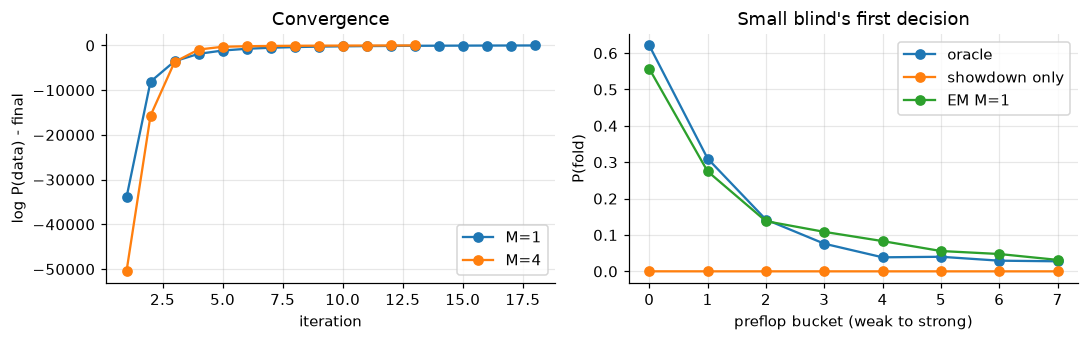

In [16]:
t0 = time.time()
EM1 = memo(f"final_M1_lam{LAM:g}", lambda: fit(D, FIT, mz=1, lam=(LAM,), verbose=False))
EMS = memo(f"final_M{M_BEST}_lam{LAM:g}", lambda: fit(D, FIT, mz=M_BEST, lam=(LAM, 2.0), init=EM1["theta"][0], verbose=False)) if M_BEST > 1 else EM1
BK_NOLINK = BK_HULHE.preflop_view()
EM_NOLINK = memo(f"final_nolink_lam{LAM:g}", lambda: fit(D, FIT, mz=1, lam=(LAM,), BK=BK_NOLINK, verbose=False))
EM_NOLINK["BK"] = BK_NOLINK
print(f"refitted in {time.time() - t0:.0f}s")

fit_mask = D.train | D.val
SHOWDOWN = posterior_mean(counts_from_truth(D, fit_mask & D.revealed), 2.0 * REF)
ORACLE = posterior_mean(counts_from_truth(D, fit_mask), 2.0 * REF)
ORACLE_COUNTS = counts_from_truth(D, fit_mask)

fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
for name, res in ((f"M=1", EM1), (f"M={M_BEST}", EMS)):
    h = np.array(res["history"])
    ax[0].plot(np.arange(1, len(h) + 1), h - h[-1], marker="o", label=name)
ax[0].set_xlabel("iteration")
ax[0].set_ylabel("log P(data) - final")
ax[0].set_title("Convergence")
ax[0].legend()
x_sb = context(0, 1, 1, 1)
for name, th in (("oracle", ORACLE), ("showdown only", SHOWDOWN), ("EM M=1", EM1["theta"][0])):
    ax[1].plot(range(K), th[x_sb, :, 0], marker="o", label=name)
ax[1].set_xlabel("preflop bucket (weak to strong)")
ax[1].set_ylabel("P(fold)")
ax[1].set_title("Small blind's first decision")
ax[1].legend()
plt.tight_layout()
plt.show()

### 5.4 What the styles captured

Each session is one bot against one opponent, so the style chain mostly separates bots with different styles and rarely switches within a session. Below: the average $\gamma_h(z)$ over each bot's hands, and the learned action probabilities of each style when opening the betting on the flop.

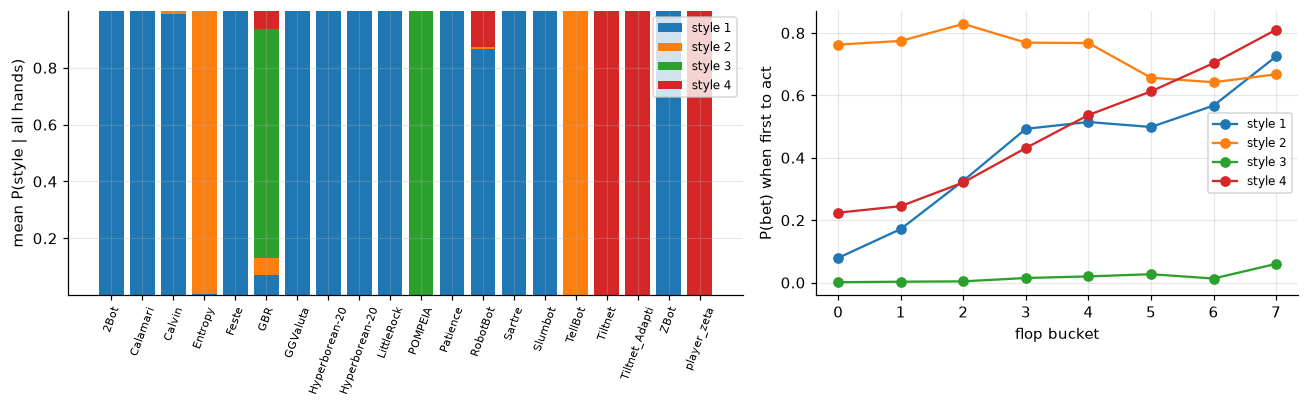

learned eps = 0.00141, initial style PMF = [0.607 0.101 0.084 0.208]


In [17]:
REC_BOT = np.array([r["name"] for r in D.records])
BOT_NAMES = sorted(set(REC_BOT))
fit_bots_names = REC_BOT[FIT.numpy()]
mean_gamma = np.stack([EMS["gamma"][torch.from_numpy(fit_bots_names == b)].mean(0).numpy() for b in BOT_NAMES])
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={"width_ratios": [1.4, 1]})
bottom = np.zeros(len(BOT_NAMES))
for z in range(EMS["M"]):
    ax[0].bar(range(len(BOT_NAMES)), mean_gamma[:, z], bottom=bottom, label=f"style {z + 1}")
    bottom += mean_gamma[:, z]
ax[0].set_xticks(range(len(BOT_NAMES)), [b[:14] for b in BOT_NAMES], rotation=70, fontsize=7)
ax[0].set_ylabel("mean P(style | all hands)")
ax[0].legend(fontsize=8)
x_open = context(1, 0, 0, 0)
for z in range(EMS["M"]):
    ax[1].plot(range(K), EMS["theta"][z, x_open, :, 2], marker="o", label=f"style {z + 1}")
ax[1].set_xlabel("flop bucket")
ax[1].set_ylabel("P(bet) when first to act")
ax[1].legend(fontsize=8)
plt.tight_layout()
plt.show()
print(f"learned eps = {EMS['eps']:.5f}, initial style PMF = {np.round(EMS['rho'].numpy(), 3)}")

### 5.5 One model per bot

Every record names its bot, so we can also fit a separate one-style model per bot. Each bot's reference is the **population** one-style model, $\alpha_{x,s}=\lambda_{\text{bot}}\,\hat\theta^{\text{pop}}_{x,s}$: unlike the context frequencies of 5.1, this reference already knows how strength drives actions, so pulling towards it does not flatten anything, and bots with few hands borrow strength from the rest. $\lambda_{\text{bot}}$ is chosen on validation, like everything else.

In [18]:
def fit_bots(recs, lam, pop):
    names = REC_BOT[recs.numpy()]
    return {b: fit(D, recs[torch.from_numpy(names == b)], mz=1, lam=(lam,), ref=pop, init=pop, verbose=False)["theta"]
            for b in BOT_NAMES if (names == b).any()}


def bot_score(models, recs):
    names = REC_BOT[recs.numpy()]
    return sum(float(e_step(D, safe_log(models[b]), recs[torch.from_numpy(names == b)])[0].sum())
               for b in BOT_NAMES if (names == b).any())


t0 = time.time()
pop_train = SELECT_LAM[LAM][1]["theta"][0]
SELECT_BOT = {}
for lam in (1.0, 3.0, 10.0, 30.0):
    SELECT_BOT[lam] = bot_score(memo(f"select_bots{lam:g}_lam{LAM:g}", lambda: fit_bots(TRAIN, lam, pop_train)), VAL)
    print(f"per-bot models, lambda = {lam:4.0f}: validation log P = {SELECT_BOT[lam]:,.1f}   ({time.time() - t0:.0f}s)")
print(f"population model (one style):     validation log P = {SELECT_LAM[LAM][0]:,.1f}")
LAM_BOT = max(SELECT_BOT, key=SELECT_BOT.get)
POP = EM1["theta"][0]
BOT_EM = memo(f"final_bots{LAM_BOT:g}_lam{LAM:g}", lambda: fit_bots(FIT, LAM_BOT, POP))
BOT_ORACLE = {b: posterior_mean(counts_from_truth(D, fit_mask & torch.from_numpy(REC_BOT == b)), 2.0 * REF)[None] for b in BOT_NAMES}
hands_per_bot = {b: int((fit_bots_names == b).sum()) for b in BOT_NAMES}
print(f"chosen lambda = {LAM_BOT:g}; hands per bot: min {min(hands_per_bot.values()):,}, max {max(hands_per_bot.values()):,}")

per-bot models, lambda =    1: validation log P = -128,260.2   (0s)
per-bot models, lambda =    3: validation log P = -128,334.5   (0s)


per-bot models, lambda =   10: validation log P = -128,712.7   (1s)
per-bot models, lambda =   30: validation log P = -129,686.0   (1s)
population model (one style):     validation log P = -145,879.2


chosen lambda = 1; hands per bot: min 2,100, max 16,800


## 6. E3: test results on ACPC hands

Everything in this section uses the test hands (the last 30% of every session) and the models chosen in Section 5. Nothing here feeds back into a modelling choice.

### 6.1 Style weights during play

On test hands the style is not known in advance. The forward recursion (eq. 10) over each whole session gives the PMF of $Z_h$ before hand $h$ is played, from the hands before it only. Card predictions then mix over styles: $p(c)\propto\sum_z P(Z_h=z\mid\text{past})\,f(c\mid z)$.

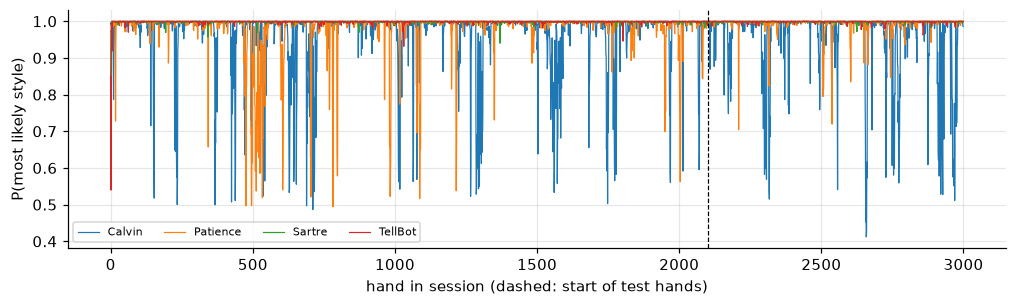

In [19]:
ALL = torch.arange(len(D))
STYLE_NAME = f"EM, {M_BEST} styles" if M_BEST > 1 else "EM, M=1 (styles)"
loge_s, _ = e_step(D, safe_log(EMS["theta"]), ALL)
grid_all = session_grid(D, ALL)
PREDS, FILTS = filter_predictive(loge_s, grid_all, torch.log(EMS["rho"]), torch.log(transition(EMS["eps"], EMS["M"])))

fig, ax = plt.subplots(figsize=(11, 2.8))
for g in grid_all[:4]:
    g = g[g >= 0]
    ax.plot(np.exp(FILTS[g].numpy()).max(1), lw=0.8, label=f"{SESSIONS[int(D.session[g[0]])][1]}")
ax.axvline(int(0.7 * grid_all.shape[1]), color="k", ls="--", lw=0.8)
ax.set_xlabel("hand in session (dashed: start of test hands)")
ax.set_ylabel("P(most likely style)")
ax.legend(fontsize=7, ncol=4)
plt.show()

### 6.2 Card prediction, folded hands included

For every test record and every street $\tau$ it reached, each estimator gives a conditional PMF of the opponent's pair from the opponent's actions up to $\tau$ and the cards visible by then. We score it against the pair actually held, which ACPC reveals even after a fold:

- **log-loss**: the average of $-\log p(\text{true pair})$. Its exponential is the number of equally likely pairs that would give the same score: uniform guessing scores $\log 1225\approx 7.11$ preflop and $\log 990\approx 6.90$ on the river;
- **top-$k$**: the fraction of records whose true pair is among the $k$ most probable (ties broken at random, so the expected fraction);
- **bucket Brier score**: the mean squared error between the predicted PMF of the bucket $S_\tau$ and the 0–1 indicators of the actual bucket.

The **single action** baseline uses only the most recent action, with showdown-only parameters, as in Terry and Mihok. The **per-bot** rows use each record's own bot model (5.5); *oracle, per bot* counts each bot's true buckets and is their reference. Each value is the mean over sessions with error bars of $\pm2$ standard deviations of that mean (central limit theorem, BT §7.4).

evaluated in 84s



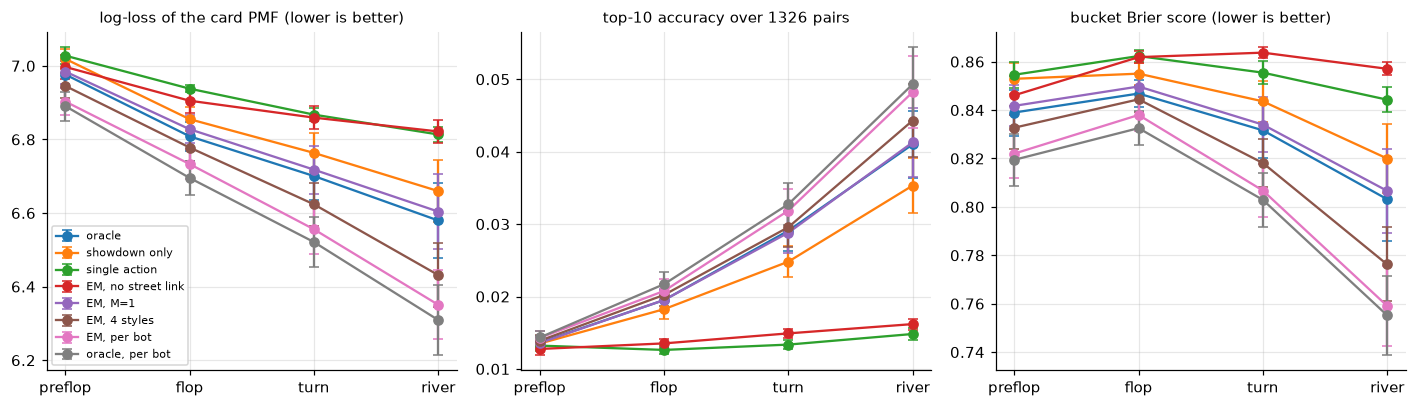

           estimator |        preflop         |          flop          |          turn          |         river         
                     |  log-loss top-10 top-1 |  log-loss top-10 top-1 |  log-loss top-10 top-1 |  log-loss top-10 top-1
              oracle |     6.976  0.014 0.001 |     6.808  0.020 0.002 |     6.701  0.029 0.003 |     6.580  0.041 0.004


       showdown only |     7.019  0.014 0.001 |     6.855  0.018 0.002 |     6.763  0.025 0.003 |     6.660  0.035 0.004
       single action |     7.028  0.013 0.001 |     6.938  0.013 0.001 |     6.867  0.013 0.001 |     6.813  0.015 0.001
  EM, no street link |     6.997  0.013 0.001 |     6.905  0.014 0.001 |     6.859  0.015 0.001 |     6.822  0.016 0.002


             EM, M=1 |     6.984  0.014 0.001 |     6.828  0.020 0.002 |     6.718  0.029 0.003 |     6.604  0.041 0.004
        EM, 4 styles |     6.945  0.014 0.001 |     6.778  0.020 0.002 |     6.624  0.030 0.003 |     6.432  0.044 0.005


         EM, per bot |     6.903  0.014 0.001 |     6.733  0.021 0.002 |     6.556  0.032 0.003 |     6.351  0.048 0.005
     oracle, per bot |     6.891  0.014 0.001 |     6.695  0.022 0.002 |     6.521  0.033 0.004 |     6.309  0.049 0.005


In [20]:
ESTIMATORS = {
    "oracle": {"theta": ORACLE[None]},
    "showdown only": {"theta": SHOWDOWN[None]},
    "single action": {"theta": SHOWDOWN[None], "last": True},
    "EM, no street link": {"theta": EM_NOLINK["theta"], "BK": BK_NOLINK},
    "EM, M=1": {"theta": EM1["theta"]},
    STYLE_NAME: {"theta": EMS["theta"], "weights": PREDS},
    "EM, per bot": {"by_bot": BOT_EM},
    "oracle, per bot": {"by_bot": BOT_ORACLE},
}


def predict_cards(est, recs, tau=None, upto=None):
    if est.get("by_bot"):
        out = torch.empty(len(recs), NC)
        names = REC_BOT[recs.numpy()]
        for b in np.unique(names):
            m = torch.from_numpy(names == b)
            sub_upto = upto[m] if upto is not None else None
            out[m] = predict_cards({"theta": est["by_bot"][b]}, recs[m], tau, sub_upto)
        return out
    L, *_ = loglik(D, safe_log(est["theta"]), recs, tau=tau, last_only=est.get("last", False),
                   BK=est.get("BK"), upto=upto)
    L = L.double()
    if est.get("weights") is not None:
        L = L + est["weights"][recs][:, :, None]
    lp = torch.logsumexp(L, 1)
    return lp - torch.logsumexp(lp, -1, keepdim=True)


def evaluate(est, recs, tau, chunk=4000):
    rows = {k: [] for k in ("nll", "top1", "top10", "top50", "brier", "session", "pbucket", "true_bucket")}
    for i in range(0, len(recs), chunk):
        r = recs[i:i + chunk]
        lp = predict_cards(est, r, tau)
        true = D.true[r]
        lt = lp[torch.arange(len(r)), true]
        above = (lp > lt[:, None]).sum(1).double()
        tied = (lp == lt[:, None]).sum(1).double()
        b = D.BK[D.hand[r], tau]
        p = torch.exp(lp)
        pb = torch.zeros(len(r), K + 1).scatter_add_(1, b + 1, p)[:, 1:]
        tb = b[torch.arange(len(r)), true]
        rows["nll"].append(-lt)
        for k in (1, 10, 50):
            rows[f"top{k}"].append(((k - above) / tied).clamp(0, 1))
        rows["brier"].append(((pb - torch.nn.functional.one_hot(tb, K).double()) ** 2).sum(1))
        rows["session"].append(D.session[r])
        rows["pbucket"].append(pb)
        rows["true_bucket"].append(tb)
    return {k: torch.cat(v) for k, v in rows.items()}


def session_mean(values, session):
    ids = torch.unique(session)
    per = torch.stack([values[session == s].mean() for s in ids])
    return float(per.mean()), float(2 * per.std() / math.sqrt(len(per)))


t0 = time.time()
RESULTS = {}
for name, est in ESTIMATORS.items():
    for tau in range(4):
        RESULTS[name, tau] = evaluate(est, TEST[D.reached[TEST] >= tau], tau)
print(f"evaluated in {time.time() - t0:.0f}s\n")

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for name in ESTIMATORS:
    for ax, metric in zip(axes, ("nll", "top10", "brier")):
        m = [session_mean(RESULTS[name, tau][metric], RESULTS[name, tau]["session"]) for tau in range(4)]
        ax.errorbar(np.arange(4), [v[0] for v in m], yerr=[v[1] for v in m], marker="o", capsize=3, label=name)
for ax, title in zip(axes, ("log-loss of the card PMF (lower is better)", "top-10 accuracy over 1326 pairs",
                            "bucket Brier score (lower is better)")):
    ax.set_xticks(range(4), STREETS)
    ax.set_title(title, fontsize=10)
axes[0].legend(fontsize=7)
plt.tight_layout()
plt.show()

print(f"{'estimator':>20} | " + " | ".join(f"{s:^22}" for s in STREETS))
print(f"{'':>20} | " + " | ".join(f"{'log-loss':>9} {'top-10':>6} {'top-1':>5}" for _ in STREETS))
for name in ESTIMATORS:
    cells = []
    for tau in range(4):
        r = RESULTS[name, tau]
        cells.append(f"{session_mean(r['nll'], r['session'])[0]:9.3f} {session_mean(r['top10'], r['session'])[0]:6.3f} "
                     f"{session_mean(r['top1'], r['session'])[0]:5.3f}")
    print(f"{name:>20} | " + " | ".join(cells))

### 6.3 Folded hands

The showdown-only model's error matters most exactly where it never trained: hands that ended in a fold. We split them by **who** folded. When the opponent folds, the fold itself is evidence about its cards; when the observer folds, the opponent's last action was a bet or raise that nobody had to show down.

In [21]:
def folder(r):
    rec = D.records[r]
    if rec["revealed"]:
        return ""
    folds = [e for e in MODEL_HANDS[rec["hand"]]["events"] if e[0] == "act" and e[3] == 0]
    return "opponent" if folds[0][2] == rec["opp"] else "observer"


FOLDER = np.array([folder(r) for r in range(len(D))])
FOLDED = {}
for name in ESTIMATORS:
    for tau in (1, 2, 3):
        recs = TEST[D.reached[TEST] >= tau]
        res = RESULTS[name, tau]
        who = FOLDER[recs.numpy()]
        for w in ("opponent", "observer"):
            m = torch.from_numpy(who == w)
            FOLDED[name, w, tau] = session_mean(res["nll"][m], res["session"][m])
print(f"{'':>20} | {'opponent folded':^29} | {'observer folded':^29}")
print(f"{'log-loss':>20} | " + " | ".join(" ".join(f"{s:>9}" for s in STREETS[1:]) for _ in range(2)))
for name in ESTIMATORS:
    print(f"{name:>20} | " + " | ".join(" ".join(f"{FOLDED[name, w, t][0]:9.3f}" for t in (1, 2, 3))
                                         for w in ("opponent", "observer")))
print(f"\ntest folded records: {int((FOLDER[TEST.numpy()] == 'opponent').sum()):,} opponent folds, "
      f"{int((FOLDER[TEST.numpy()] == 'observer').sum()):,} observer folds")

                     |        opponent folded        |        observer folded       
            log-loss |      flop      turn     river |      flop      turn     river
              oracle |     6.685     6.525     6.254 |     6.819     6.683     6.500
       showdown only |     6.753     6.651     6.542 |     6.852     6.720     6.537
       single action |     6.858     6.774     6.809 |     6.944     6.838     6.743
  EM, no street link |     6.927     6.909     7.022 |     6.878     6.813     6.751
             EM, M=1 |     6.717     6.561     6.405 |     6.832     6.698     6.518
        EM, 4 styles |     6.673     6.594     6.324 |     6.786     6.609     6.382
         EM, per bot |     6.643     6.524     6.453 |     6.735     6.571     6.332
     oracle, per bot |     6.538     6.382     6.032 |     6.713     6.528     6.301

test folded records: 18,197 opponent folds, 18,197 observer folds


### 6.4 Calibration of bucket predictions

Pool every (record, bucket) pair on the river, group them by the predicted probability, and compare with how often the bucket was actually the true one. A calibrated model lies on the diagonal.

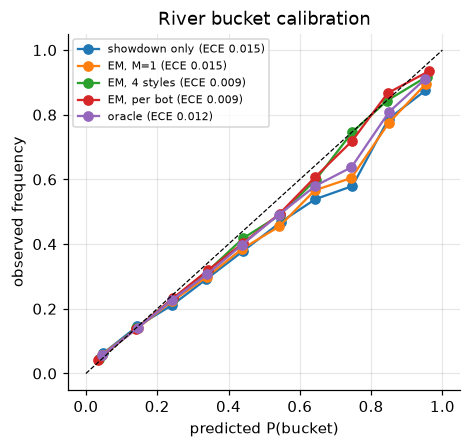

In [22]:
def reliability(p, y, bins=10, min_count=30):
    edges = np.linspace(0, 1, bins + 1)
    idx = np.clip(np.digitize(p, edges) - 1, 0, bins - 1)
    n = np.bincount(idx, minlength=bins)
    ok = n > min_count
    pred = np.bincount(idx, p, minlength=bins)[ok] / n[ok]
    freq = np.bincount(idx, y, minlength=bins)[ok] / n[ok]
    return pred, freq, float(np.sum(n[ok] * np.abs(pred - freq)) / len(p))


fig, ax = plt.subplots(figsize=(4.6, 4.2))
for name in ("showdown only", "EM, M=1", STYLE_NAME, "EM, per bot", "oracle"):
    r = RESULTS[name, 3]
    pred, freq, ece = reliability(r["pbucket"].reshape(-1).numpy(),
                                  torch.nn.functional.one_hot(r["true_bucket"], K).reshape(-1).numpy())
    ax.plot(pred, freq, marker="o", label=f"{name} (ECE {ece:.3f})")
ax.plot([0, 1], [0, 1], "k--", lw=0.8)
ax.set_xlabel("predicted P(bucket)")
ax.set_ylabel("observed frequency")
ax.set_title("River bucket calibration")
ax.legend(fontsize=7)
plt.show()

### 6.5 Parameter error

$\sum_a\theta^{\text{oracle}}(a)\log\big(\theta^{\text{oracle}}(a)/\hat\theta(a)\big)$ per cell $(x,s)$, averaged with weights equal to how often each cell occurs. Against the population oracle, the style model's $\hat\theta$ pools the expected counts of all styles. Against each bot's own oracle, we compare the population model with the per-bot models.

In [23]:
weight = ORACLE_COUNTS.sum(-1)


def param_error(theta_hat, truth=ORACLE, w=weight):
    kl = (truth * (safe_log(truth) - safe_log(theta_hat)) * LEGAL[:, None, :]).sum(-1)
    per_street = []
    for s in range(4):
        xs = [x for x in range(NX) if decode(x)[0] == s]
        per_street.append(float((kl * w)[xs].sum() / w[xs].sum()))
    return float((kl * w).sum() / w.sum()), per_street


pooled = EMS["counts"].sum(0) + 2.0 * REF
pooled = pooled / pooled.sum(-1, keepdim=True)
print(f"{'against the population oracle':>30} | {'overall':>8} | " + " | ".join(f"{s:>8}" for s in STREETS))
for name, th in (("showdown only", SHOWDOWN), ("EM, M=1", EM1["theta"][0]), (f"{STYLE_NAME} (pooled)", pooled)):
    total, by = param_error(th)
    print(f"{name:>30} | {total:8.4f} | " + " | ".join(f"{v:8.4f}" for v in by))

bot_err = {"population EM, M=1": [0.0, 0.0], "EM, per bot": [0.0, 0.0]}
for b in BOT_NAMES:
    w = counts_from_truth(D, fit_mask & torch.from_numpy(REC_BOT == b)).sum(-1)
    for name, th in (("population EM, M=1", POP), ("EM, per bot", BOT_EM[b][0])):
        bot_err[name][0] += param_error(th, BOT_ORACLE[b][0], w)[0] * float(w.sum())
        bot_err[name][1] += float(w.sum())
print("\nagainst each bot's own oracle, averaged over bots by number of actions:")
for name, (v, n) in bot_err.items():
    print(f"{name:>30}: {v / n:.4f}")

 against the population oracle |  overall |  preflop |     flop |     turn |    river
                 showdown only |   0.4747 |   0.6980 |   0.4330 |   0.3743 |   0.2949
                       EM, M=1 |   0.0074 |   0.0084 |   0.0106 |   0.0039 |   0.0050
         EM, 4 styles (pooled) |   0.0058 |   0.0066 |   0.0085 |   0.0036 |   0.0032



against each bot's own oracle, averaged over bots by number of actions:
            population EM, M=1: 0.2417
                   EM, per bot: 0.0150


### 6.6 Decision value on the river

Does better card reading make better decisions? On the river the question can be answered exactly with the ACPC truth. We take every test hand in which the opponent bets or raises on the river and the observer must respond. Calling ends the hand (no more cards, and the observer's call closes the betting), so with the opponent's real cards the value of calling is known exactly: $+P_{\text{now}}$ if the observer wins, $-b$ if it loses, half of each on a tie. Folding is worth 0.

Each estimator reads the opponent's pair from its actions **before** the decision only, computes $q=P(\text{win})$ and calls iff $q>b/(P_{\text{now}}+b)$ (Proposition 3). We report the realized chips per decision, compared with:

- **always call**;
- **the bot's actual choice**, scoring its raises as calls (a raise can only do better when ahead, so this slightly understates the bot);
- **perfect information**: call exactly when ahead, the ceiling.

Differences against showdown-only are computed decision by decision, which removes most of the luck shared by all strategies.

17,192 river decisions in test hands; the observer is ahead in 35.7%



              strategy |   chips/decision |   vs showdown only
                oracle |   +38.84 ±  6.05 |     -0.13 ±  0.29
         showdown only |   +38.97 ±  6.21 |     +0.00 ±  0.00
    EM, no street link |   +39.48 ±  6.81 |     +0.51 ±  0.87
               EM, M=1 |   +38.64 ±  5.96 |     -0.34 ±  0.39
          EM, 4 styles |   +40.02 ±  6.55 |     +1.04 ±  0.62
           EM, per bot |   +40.38 ±  6.49 |     +1.41 ±  0.68
       oracle, per bot |   +40.58 ±  6.48 |     +1.60 ±  0.66
           always call |   +37.48 ±  6.98 |     -1.50 ±  1.08
   bot's actual choice |   +37.22 ±  6.73 |     -1.75 ±  1.03
   perfect information |   +50.07 ±  6.42 |    +11.09 ±  0.72


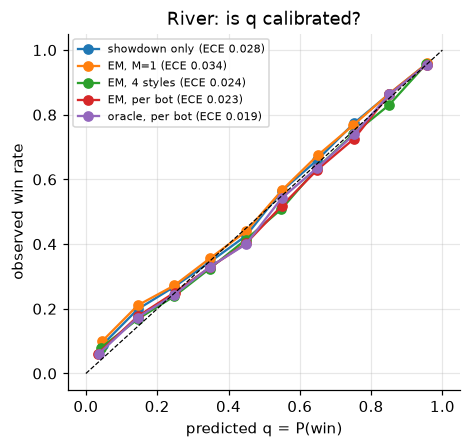

In [24]:
def river_decisions(recs):
    out = []
    for r in recs.tolist():
        rec = D.records[r]
        acts = [e for e in MODEL_HANDS[rec["hand"]]["events"] if e[0] == "act"]
        n_opp = 0
        for i, e in enumerate(acts):
            if e[2] == rec["opp"]:
                n_opp += 1
                if e[1] == 3 and e[3] == 2 and i + 1 < len(acts) and acts[i + 1][2] != rec["opp"]:
                    out.append((r, n_opp, acts[i + 1]))
                    break
    return out


def win_vector(obs_cards, board):
    valid = torch.from_numpy(consistent(obs_cards + board))
    ours = hand_rank(torch.tensor([obs_cards + board]))[0]
    pairs = torch.where(valid[:, None], COMBOS_T, torch.tensor(obs_cards))
    theirs = hand_rank(torch.cat([pairs, torch.tensor(board).expand(NC, 5)], 1))
    return valid * ((ours > theirs).double() + 0.5 * (ours == theirs).double())


DECISIONS = river_decisions(TEST)
DEC_RECS = torch.tensor([d[0] for d in DECISIONS])
DEC_UPTO = torch.tensor([d[1] for d in DECISIONS])
POT = torch.tensor([d[2][5] for d in DECISIONS], dtype=torch.double)
CALL = torch.tensor([d[2][6] for d in DECISIONS], dtype=torch.double)
BOT_CHOICE = torch.tensor([d[2][3] for d in DECISIONS])
WIN = torch.stack([win_vector(D.records[r]["vis"][:2], MODEL_HANDS[D.records[r]["hand"]]["board"])
                   for r in DEC_RECS.tolist()])
W_TRUE = WIN[torch.arange(len(DECISIONS)), D.true[DEC_RECS]]
VALUE_CALL = W_TRUE * POT - (1 - W_TRUE) * CALL
THRESH = CALL / (POT + CALL)
print(f"{len(DECISIONS):,} river decisions in test hands; the observer is ahead in {float((W_TRUE == 1).double().mean()):.1%}")

Q = {name: (torch.exp(predict_cards(est, DEC_RECS, 3, DEC_UPTO)) * WIN).sum(1)
     for name, est in ESTIMATORS.items() if name != "single action"}
GAIN = {name: torch.where(q > THRESH, VALUE_CALL, torch.zeros(())) for name, q in Q.items()}
GAIN["always call"] = VALUE_CALL
GAIN["bot's actual choice"] = torch.where(BOT_CHOICE > 0, VALUE_CALL, torch.zeros(()))
GAIN["perfect information"] = VALUE_CALL.clamp(min=0)
dec_session = D.session[DEC_RECS]
base = GAIN["showdown only"]
print(f"\n{'strategy':>22} | {'chips/decision':>16} | {'vs showdown only':>18}")
for name, g in GAIN.items():
    m, se = session_mean(g, dec_session)
    dm, dse = session_mean(g - base, dec_session)
    print(f"{name:>22} | {m:+8.2f} ± {se:5.2f} | {dm:+9.2f} ± {dse:5.2f}")

fig, ax = plt.subplots(figsize=(4.6, 4.2))
for name in ("showdown only", "EM, M=1", STYLE_NAME, "EM, per bot", "oracle, per bot"):
    pred, freq, ece = reliability(Q[name].numpy(), W_TRUE.numpy(), bins=10, min_count=20)
    ax.plot(pred, freq, marker="o", label=f"{name} (ECE {ece:.3f})")
ax.plot([0, 1], [0, 1], "k--", lw=0.8)
ax.set_xlabel("predicted q = P(win)")
ax.set_ylabel("observed win rate")
ax.set_title("River: is q calibrated?")
ax.legend(fontsize=7)
plt.show()

### 6.7 Detecting a change of opponent in real play

The style chain cannot show switching on ACPC data, because every bot keeps one strategy per match: $\varepsilon$ is learned as essentially zero, and in Leduc (Section 11) the switching opponents are generated by the model itself. To test detection on play the model did not generate, we **splice** test hands of two real bots into one sequence: segments of bot A and bot B alternate, with lengths drawn with mean 150 hands, so the switch points are known but every hand is real.

Each bot model of 5.5 plays the role of a style, and the forward recursion (eq. 10) with a small switching probability tracks $P(\text{bot}\mid\text{hands so far})$ over all bots. We compare:

- **card-aware**: the per-bot models, whose likelihood includes the cards shown at showdown and reads folded hands through strength;
- **card-blind**: per-bot action frequencies by context only, the same recursion;
- **sliding window**: the card-blind bot that best explains the last 50 hands.

We report the median number of hands until the new bot has probability above 0.9, the fraction of segments never detected, and how often the most probable bot is the right one.

per-record evidence under 20 bot models in 12s


30 spliced sessions of 2000 real test hands, 375 switches between 19 bots

                 | median delay | mean delay | never detected | right bot
      card-aware |           11 |       30.3 |          21.9% |     78.7%
      card-blind |           12 |       33.1 |          35.2% |     71.9%
  sliding window |           35 |       34.6 |          20.5% |     58.9%


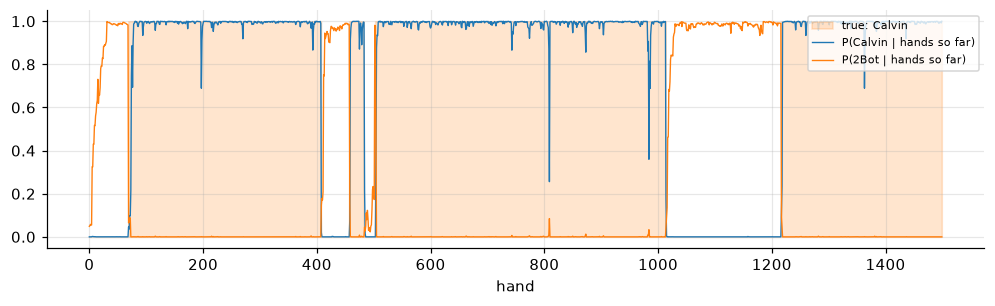

In [25]:
test_bots = REC_BOT[TEST.numpy()]
BOT_INDEX = {b: i for i, b in enumerate(BOT_NAMES)}
t0 = time.time()
E_AWARE = torch.stack([e_step(D, safe_log(BOT_EM[b]), TEST)[0][:, 0] for b in BOT_NAMES], 1)
blind = torch.stack([context_reference(D, fit_mask & torch.from_numpy(REC_BOT == b))[:, 0, :] for b in BOT_NAMES])
ev_test, loc_test = record_events(D, TEST)
E_BLIND = torch.zeros(len(TEST), len(BOT_NAMES)).index_add_(
    0, loc_test, torch.log(blind[:, D.ev_x[ev_test], D.ev_a[ev_test]]).T)
print(f"per-record evidence under {len(BOT_NAMES)} bot models in {time.time() - t0:.0f}s")

test_pos = {int(r): i for i, r in enumerate(TEST.tolist())}
bot_sessions = {}
for s in torch.unique(D.session[TEST]).tolist():
    rows = [test_pos[int(r)] for r in TEST[D.session[TEST] == s].tolist()]
    bot_sessions.setdefault(SESSIONS[s][1], []).append(rows)


def splice(a, b, n, gen, mean_len=150):
    seq, truth, who = [], [], 0
    while len(seq) < n:
        bot = (a, b)[who]
        rows = bot_sessions[bot][gen.integers(len(bot_sessions[bot]))]
        length = min(int(gen.geometric(1 / mean_len)) + 10, len(rows))
        start = gen.integers(0, len(rows) - length + 1)
        seq += rows[start:start + length]
        truth += [BOT_INDEX[bot]] * length
        who = 1 - who
    return torch.tensor(seq[:n]), np.array(truth[:n])


def track(evidence, eps=1 / 300):
    nb = evidence.shape[1]
    log_g = torch.log(torch.full((nb, nb), eps / (nb - 1)) + torch.eye(nb) * (1 - eps - eps / (nb - 1)))
    f = torch.full((nb,), -math.log(nb))
    out = torch.empty_like(evidence)
    for t in range(len(evidence)):
        f = torch.logsumexp(f[:, None] + log_g, 0) + evidence[t]
        f = f - torch.logsumexp(f, 0)
        out[t] = f
    return torch.exp(out).numpy()


def window(evidence, w=50):
    c = torch.cumsum(evidence, 0)
    lagged = torch.cat([torch.zeros(w, evidence.shape[1]), c[:-w]])
    s = c - lagged
    return torch.nn.functional.one_hot(s.argmax(1), evidence.shape[1]).double().numpy()


def detection(post, truth, threshold=0.9):
    starts = np.r_[0, np.nonzero(truth[1:] != truth[:-1])[0] + 1]
    ends = np.r_[starts[1:], len(truth)]
    delays, missed = [], 0
    for s, e in zip(starts[1:], ends[1:]):
        hit = np.nonzero(post[s:e, truth[s]] > threshold)[0]
        if len(hit):
            delays.append(hit[0])
        else:
            missed += 1
    accuracy = float((post.argmax(1) == truth).mean())
    return delays, missed, len(starts) - 1, accuracy


gen = np.random.default_rng(11)
eligible = [b for b in BOT_NAMES if b in bot_sessions and sum(map(len, bot_sessions[b])) >= 1500]
SPLICE = {"card-aware": [[], 0, 0, []], "card-blind": [[], 0, 0, []], "sliding window": [[], 0, 0, []]}
for trial in range(30):
    a, b = gen.choice(eligible, 2, replace=False)
    seq, truth = splice(a, b, 2000, gen)
    for name, post in (("card-aware", track(E_AWARE[seq])), ("card-blind", track(E_BLIND[seq])),
                       ("sliding window", window(E_BLIND[seq]))):
        d, miss, n, acc = detection(post, truth)
        SPLICE[name][0] += d
        SPLICE[name][1] += miss
        SPLICE[name][2] += n
        SPLICE[name][3].append(acc)
print(f"30 spliced sessions of 2000 real test hands, {SPLICE['card-aware'][2]} switches between {len(eligible)} bots\n")
print(f"{'':>16} | {'median delay':>12} | {'mean delay':>10} | {'never detected':>14} | {'right bot':>9}")
for name, (d, miss, n, acc) in SPLICE.items():
    print(f"{name:>16} | {np.median(d) if d else float('nan'):12.0f} | {np.mean(d) if d else float('nan'):10.1f} | "
          f"{miss / n:14.1%} | {np.mean(acc):9.1%}")

seq, truth = splice(eligible[0], eligible[1], 1500, np.random.default_rng(3))
post = track(E_AWARE[seq])
fig, ax = plt.subplots(figsize=(11, 2.8))
ax.fill_between(np.arange(len(truth)), 0, (truth == BOT_INDEX[eligible[1]]).astype(float), step="mid",
                color="tab:orange", alpha=0.2, label=f"true: {eligible[1]}")
ax.plot(post[:, BOT_INDEX[eligible[1]]], lw=0.9, label=f"P({eligible[1]} | hands so far)")
ax.plot(post[:, BOT_INDEX[eligible[0]]], lw=0.9, label=f"P({eligible[0]} | hands so far)")
ax.set_xlabel("hand")
ax.legend(fontsize=7, loc="upper right")
plt.show()

## 7. Decisions and certificates

### 7.1 One river decision from a test hand

Section 6.6 scored thousands of river decisions; here we look inside one. We take the test decision whose $q$ under the style model is closest to its threshold, the hardest kind. Everything below uses only what the observer saw before deciding: its own cards, the board and the opponent's actions up to the bet it faces.

**Proposition 3.** With pot $P_{\text{now}}$ (including the opponent's bet) and $b$ to call, calling beats folding iff $q>b/(P_{\text{now}}+b)$, where $q=\sum_c p(c)\big(\mathbf{1}[o\succ c]+\tfrac12\mathbf{1}[o\sim c]\big)$ is the probability of winning. With $P_{\text{now}}=P+b$ this is the paper's $b/(P+2b)$.

The pair PMF uses the style model: the style PMF before the hand (from earlier hands of the session) times the probability of this hand's actions under each style.

In [26]:
def style_and_cards(theta, rec_idx, prior_log, upto):
    L, *_ = loglik(D, safe_log(theta), torch.tensor([rec_idx]), tau=3, upto=torch.tensor([upto]))
    joint = L[0].double() + prior_log[:, None]
    return torch.softmax(joint.reshape(-1), 0).reshape(joint.shape)


i_case = int(torch.argmin((Q[STYLE_NAME] - THRESH).abs()))
DEC, DEC_N, OBS_ACTION = DECISIONS[i_case]
dec = D.records[DEC]
dec_hand = MODEL_HANDS[dec["hand"]]
obs_cards, board = dec["vis"][:2], dec_hand["board"]
WIN_DEC, THRESHOLD = WIN[i_case], float(THRESH[i_case])
pot_now, to_call = float(POT[i_case]), float(CALL[i_case])
JOINT = style_and_cards(EMS["theta"], DEC, PREDS[DEC], DEC_N)
q_mean = float((JOINT.sum(0) * WIN_DEC).sum())
valid_dec = consistent(obs_cards + board)
print("observer holds", " ".join(card_str(c) for c in obs_cards), "| board", " ".join(card_str(c) for c in board))
print("opponent's actions before the decision:", [(STREETS[t], ACTIONS[a]) for t, x, a in dec["acts"][:DEC_N]])
print(f"pot {pot_now:.0f}, to call {to_call:.0f}: call iff q > {THRESHOLD:.3f}")
print(f"q = P(win) = {q_mean:.3f}  ->  {'call' if q_mean > THRESHOLD else 'fold'}"
      f"   (the bot actually chose: {ACTIONS[OBS_ACTION[3]]})")
print("style PMF given past hands and this hand:", np.round(JOINT.sum(1).numpy(), 3))
print("opponent actually held", "".join(card_str(c) for c in COMBOS[dec["true"]]),
      f"(observer {'wins' if WIN_DEC[dec['true']] == 1 else 'loses' if WIN_DEC[dec['true']] == 0 else 'ties'})")

observer holds 6h 4d | board 7d 6c Jd 9s Tc
opponent's actions before the decision: [('preflop', 'c'), ('flop', 'c'), ('turn', 'c'), ('river', 'r')]
pot 40, to call 20: call iff q > 0.333
q = P(win) = 0.333  ->  fold   (the bot actually chose: c)
style PMF given past hands and this hand: [0.    0.    0.004 0.996]
opponent actually held 2hTh (observer loses)


### 7.2 The certificate (Definition 1)

The parameters are uncertain, so $q$ is a random variable. We draw $(\theta^{(k)},Z^{(k)})$ from their conditional distribution: $Z^{(k)}$ from the style PMF, $\theta^{(k)}_{z,x,s}$ from the joint PDF with parameters `alpha` (drawn through independent gamma variables, normalized). For each draw we recompute the pair PMF and $q^{(k)}$. Then

- $\pi^\star$ is the fraction of draws in which $d^\star$ is still the better action;
- $\Delta$ is the mean margin $G=U(d^\star)-U(\text{other})$ in chips, and $[\ell,u]$ the 5% and 95% points of $G$.

The simulation error of $\pi^\star$ has standard deviation at most $1/(2\sqrt{k})$ (weak law of large numbers).

The recommendation of 7.1 plugs in the mean parameters; $d^\star$ here averages the chip gain over the parameter draws. For a decision as close as this one the two can land on different sides of the threshold, and a $\pi^\star$ near one half says exactly that: given what is known about this opponent, the decision is a coin flip.

d* = call,  pi* = 0.535,  Delta = +0.00 chips,  90% interval for the margin: [-0.76, +0.85]


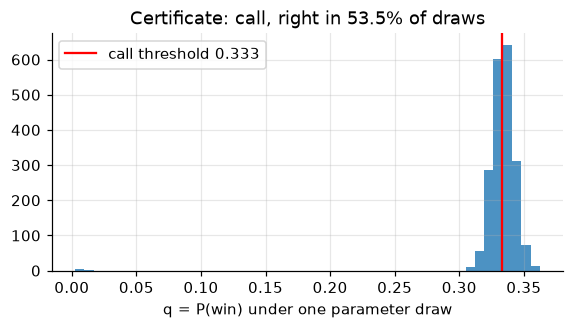

In [27]:
def sample_theta(alpha, n, gen=None):
    conc = torch.where(alpha > 0, alpha, torch.ones_like(alpha))
    g = torch.distributions.Gamma(conc, torch.ones_like(conc)).sample((n,))
    g = torch.where(alpha > 0, g, torch.zeros_like(g))
    return g / g.sum(-1, keepdim=True).clamp(min=1e-300)


def certificate(rec_idx, upto, win, pot, call, n=2000, model=None, pred=None):
    model = EMS if model is None else model
    pred = PREDS if pred is None else pred
    ev, loc = record_events(D, torch.tensor([rec_idx]), 3, upto=torch.tensor([upto]))
    b = event_buckets(D, ev)
    valid = valid_at(D, torch.tensor([rec_idx]), 3)[0]
    style_w = style_and_cards(model["theta"], rec_idx, pred[rec_idx], upto).sum(1)
    z = torch.multinomial(style_w, n, replacement=True)
    qs = torch.empty(n)
    for zz in range(model["M"]):
        idx = torch.nonzero(z == zz).squeeze(1)
        if len(idx) == 0:
            continue
        th = sample_theta(model["alpha"][zz], len(idx))
        lt = torch.log(th[:, D.ev_x[ev], :, D.ev_a[ev]].clamp(min=1e-300)).permute(1, 0, 2)
        g = torch.gather(lt, 2, b.clamp(min=0)[None].expand(len(idx), -1, -1)).sum(1)
        g = torch.where(valid[None], g, torch.tensor(-torch.inf))
        qs[idx] = (torch.softmax(g, -1) * win[None]).sum(-1)
    u_call = qs * pot - (1 - qs) * call
    d_star = "call" if float(u_call.mean()) > 0 else "fold"
    margin = u_call if d_star == "call" else -u_call
    return {"q": qs, "d": d_star, "pi": float((margin > 0).double().mean()), "delta": float(margin.mean()),
            "interval": (float(torch.quantile(margin, 0.05)), float(torch.quantile(margin, 0.95)))}


torch.manual_seed(3)
CERT = certificate(DEC, DEC_N, WIN_DEC, pot_now, to_call)
print(f"d* = {CERT['d']},  pi* = {CERT['pi']:.3f},  Delta = {CERT['delta']:+.2f} chips,  "
      f"90% interval for the margin: [{CERT['interval'][0]:+.2f}, {CERT['interval'][1]:+.2f}]")
fig, ax = plt.subplots(figsize=(6, 2.8))
ax.hist(CERT["q"].numpy(), bins=50, color="tab:blue", alpha=0.8)
ax.axvline(THRESHOLD, color="red", label=f"call threshold {THRESHOLD:.3f}")
ax.set_xlabel("q = P(win) under one parameter draw")
ax.set_title(f"Certificate: {CERT['d']}, right in {CERT['pi']:.1%} of draws")
ax.legend()
plt.show()

## 8. Explaining the belief

### 8.1 The evidence split (Proposition 4)

Let $E$ be "the opponent's pair is in the top 20% on the final board". Each observed event $e_k$ (an opponent action or a board card) gets the weight

$$
w_k=\log\frac{P(e_k\mid E,e_{<k})}{P(e_k\mid E^c,e_{<k})},
$$

and the weights add up exactly to the change in the log-odds of $E$. We track the joint PMF of (style, pair) event by event, so the split is exact for the style model too. The observer's own actions carry no information about the opponent's cards and get weight 0, so they are left out.

log-odds of E: start -1.587, end -0.899, change +0.6886
sum of the weights w_k: +0.6886


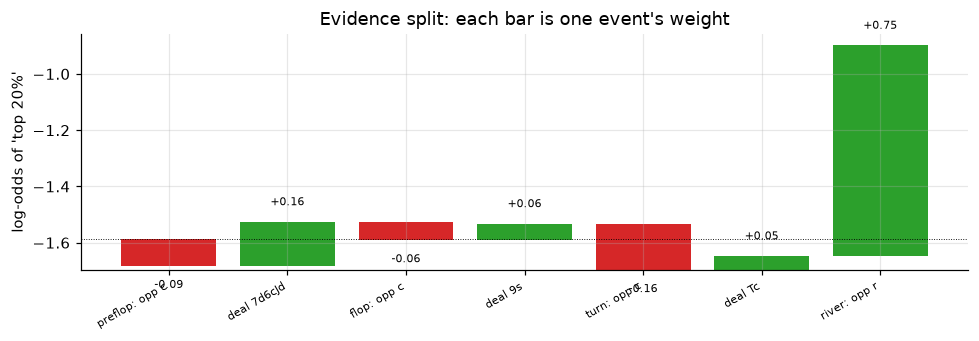

In [28]:
STRONG = strength(torch.tensor([board]))[0]
E_SET = (STRONG >= 0.8) & torch.from_numpy(valid_dec)


def event_trace(rec_idx, theta, prior_log, upto, override=None):
    rec = D.records[rec_idx]
    h = MODEL_HANDS[rec["hand"]]
    obs = rec["vis"][:2]
    p = torch.exp(prior_log)[:, None] * torch.from_numpy(consistent(obs)).double()[None]
    p = p / p.sum()
    steps = []
    k_opp = 0
    for i, e in enumerate(h["events"]):
        if e[0] == "deal":
            new = h["board"][[0, 3, 4, 5][e[1] - 1]:[0, 3, 4, 5][e[1]]]
            lik = torch.from_numpy(consistent(new)).double()[None].expand_as(p)
            label = "deal " + "".join(card_str(c) for c in new)
        elif e[2] == rec["opp"]:
            if k_opp >= upto:
                break
            a = e[3] if override is None or override[0] != k_opp else override[1]
            k_opp += 1
            s = D.BK[rec["hand"], e[1]].clamp(min=0)
            lik = theta[:, e[4], :, a][:, s]
            label = f"{STREETS[e[1]]}: opp {ACTIONS[a]}"
        else:
            continue
        pe = (p[:, E_SET] * lik[:, E_SET]).sum() / p[:, E_SET].sum()
        pn = (p[:, ~E_SET] * lik[:, ~E_SET]).sum() / p[:, ~E_SET].sum()
        steps.append((label, float(torch.log(pe / pn))))
        p = p * lik
        p = p / p.sum()
    return p, steps


p0 = torch.exp(PREDS[DEC])[:, None] * torch.from_numpy(consistent(obs_cards)).double()[None]
p0 = p0 / p0.sum()
P_FINAL, STEPS = event_trace(DEC, EMS["theta"], PREDS[DEC], DEC_N)
odds = lambda p: float(torch.log(p[:, E_SET].sum() / p[:, ~E_SET].sum()))
print(f"log-odds of E: start {odds(p0):+.3f}, end {odds(P_FINAL):+.3f}, change {odds(P_FINAL) - odds(p0):+.4f}")
print(f"sum of the weights w_k: {sum(w for _, w in STEPS):+.4f}")

fig, ax = plt.subplots(figsize=(9, 3.2))
level = odds(p0)
for i, (label, w) in enumerate(STEPS):
    ax.bar(i, w, bottom=level, color="tab:green" if w >= 0 else "tab:red")
    ax.text(i, level + w + (0.05 if w >= 0 else -0.05), f"{w:+.2f}", ha="center", va="bottom" if w >= 0 else "top", fontsize=7)
    level += w
ax.axhline(odds(p0), color="k", lw=0.6, ls=":")
ax.set_xticks(range(len(STEPS)), [l for l, _ in STEPS], rotation=30, ha="right", fontsize=7)
ax.set_ylabel("log-odds of 'top 20%'")
ax.set_title("Evidence split: each bar is one event's weight")
plt.tight_layout()
plt.show()

### 8.2 What-if explanations

For each opponent action we try every other legal action in the same context, recompute the pair PMF and $q$, and check whether the recommendation changes. A change that flips the decision is reported with the size of the weight change $|w_k-w_k'|$; the smallest such change is the explanation.

In [29]:
opp_acts = [(i, e) for i, e in enumerate(dec_hand["events"]) if e[0] == "act" and e[2] == dec["opp"]][:DEC_N]
base_d = "call" if q_mean > THRESHOLD else "fold"
w_opp = [w for (label, w) in STEPS if "opp" in label]
flips = []
print(f"recommendation with the actual actions: {base_d} (q = {q_mean:.3f})")
for k, (i, e) in enumerate(opp_acts):
    for a in range(3):
        if a == e[3] or not LEGAL[e[4], a]:
            continue
        p_alt, steps_alt = event_trace(DEC, EMS["theta"], PREDS[DEC], DEC_N, override=(k, a))
        q_alt = float((p_alt.sum(0) * WIN_DEC).sum())
        d_alt = "call" if q_alt > THRESHOLD else "fold"
        w_alt = [w for (label, w) in steps_alt if "opp" in label][k]
        print(f"  {STREETS[e[1]]:>7}: {ACTIONS[e[3]]} -> {ACTIONS[a]}:  q = {q_alt:.3f}  ->  {d_alt}"
              f"{'   (flips)' if d_alt != base_d else ''}")
        if d_alt != base_d:
            flips.append((abs(w_opp[k] - w_alt), STREETS[e[1]], ACTIONS[e[3]], ACTIONS[a], d_alt))
if flips:
    best = min(flips)
    print(f"\nExplanation: had the opponent played {best[3]} instead of {best[2]} on the {best[1]}, "
          f"the recommendation would be {best[4]} rather than {base_d}.")
else:
    print("\nNo single change of an opponent action flips the recommendation: it is robust to each action.")

recommendation with the actual actions: fold (q = 0.333)
  preflop: c -> r:  q = 0.337  ->  call   (flips)
     flop: c -> r:  q = 0.207  ->  fold
     turn: c -> r:  q = 0.128  ->  fold
    river: r -> c:  q = 0.716  ->  call   (flips)

Explanation: had the opponent played r instead of c on the preflop, the recommendation would be call rather than fold.


## 9. Pattern statistics

### 9.1 Style indices with intervals

Functions of the random parameters, so random variables themselves. For each style we report the mean and a 90% interval from 2000 draws of $\theta_z$:

- **Bluff$_t$**: probability of betting with the two weakest buckets when first to act on street $t$;
- **SlowPlay$_t$**: probability of checking with the two strongest buckets when first to act;
- **FoldToBet$_t$**: probability of folding when facing a single bet after checking, averaged over buckets with the style's own bucket frequencies in that spot.

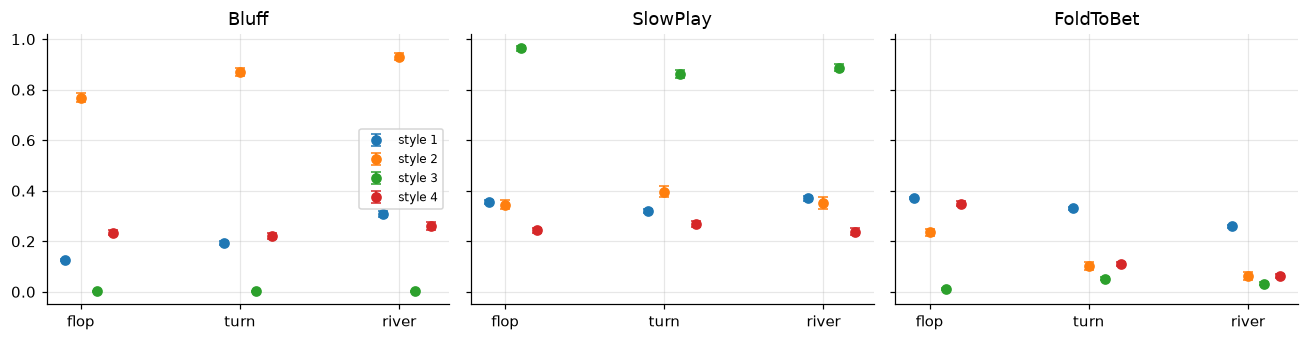

In [30]:
def style_indices(model, n=2000):
    out = {}
    for z in range(model["M"]):
        th = sample_theta(model["alpha"][z], n)
        for t in (1, 2, 3):
            x_open, x_face = context(t, 0, 0, 0), context(t, 1, 1, 0)
            reach = model["counts"][z, x_face].sum(-1)
            reach = reach / reach.sum()
            out["Bluff", t, z] = th[:, x_open, :2, 2].mean(-1)
            out["SlowPlay", t, z] = th[:, x_open, -2:, 1].mean(-1)
            out["FoldToBet", t, z] = (th[:, x_face, :, 0] * reach).sum(-1)
    return out


IDX = style_indices(EMS)
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2), sharey=True)
for ax, name in zip(axes, ("Bluff", "SlowPlay", "FoldToBet")):
    for z in range(EMS["M"]):
        v = [IDX[name, t, z] for t in (1, 2, 3)]
        mean = [float(s.mean()) for s in v]
        lo = [mean[i] - float(torch.quantile(v[i], 0.05)) for i in range(3)]
        hi = [float(torch.quantile(v[i], 0.95)) - mean[i] for i in range(3)]
        ax.errorbar(np.arange(3) + 0.1 * (z - 1), mean, yerr=[lo, hi], marker="o", capsize=3, ls="none", label=f"style {z + 1}")
    ax.set_xticks(range(3), STREETS[1:])
    ax.set_title(name)
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

### 9.2 The leak map

$\text{Leak}_{x,s}(z)=\sum_a\theta_{z,x,s}(a)\log\big(\theta_{z,x,s}(a)/\theta^{\text{ref}}_{x,s}(a)\big)$, the expected log-ratio between a style's play and a reference. With no equilibrium for full HULHE at hand, the reference is the population strategy estimated from all training hands with their true cards. Cells are weighted by how often the style reaches them: large values mark where a style deviates most, and so where it is most exploitable relative to the population.

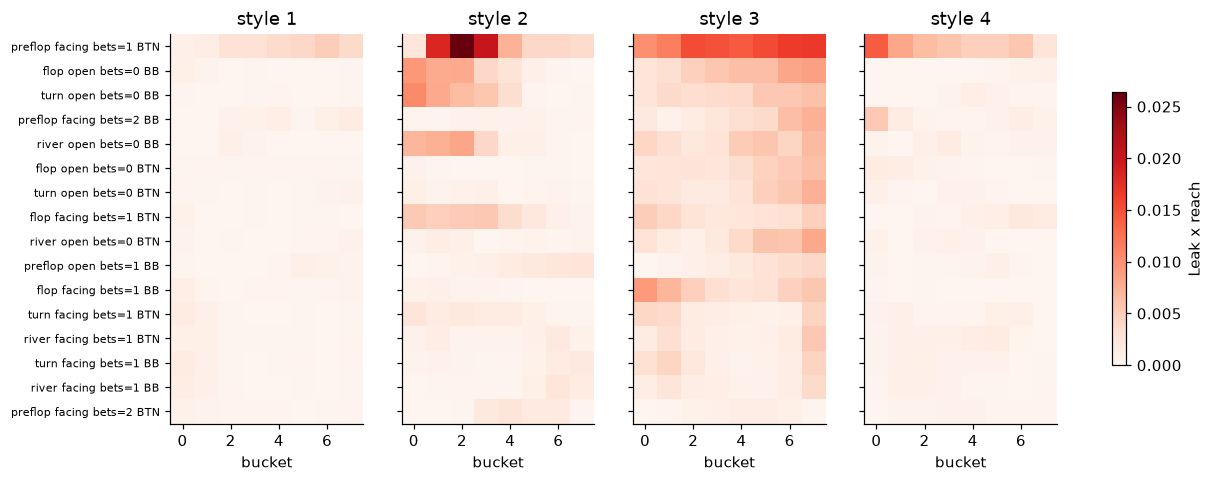

style 1: largest leaks at preflop facing bets=1 BTN, bucket 6; preflop facing bets=1 BTN, bucket 5; preflop facing bets=1 BTN, bucket 7
style 2: largest leaks at preflop facing bets=1 BTN, bucket 2; preflop facing bets=1 BTN, bucket 3; preflop facing bets=1 BTN, bucket 1
style 3: largest leaks at preflop facing bets=1 BTN, bucket 7; preflop facing bets=1 BTN, bucket 6; preflop facing bets=1 BTN, bucket 5
style 4: largest leaks at preflop facing bets=1 BTN, bucket 0; preflop facing bets=1 BTN, bucket 1; preflop facing bets=1 BTN, bucket 2


In [31]:
def leak_map(model, ref):
    th = model["theta"]
    kl = (th * (safe_log(th) - safe_log(ref)[None]) * LEGAL[None, :, None, :]).sum(-1)
    reach = model["counts"].sum(-1)
    reach = reach / reach.sum((1, 2), keepdim=True)
    return kl, kl * reach


KL_CELL, LEAK = leak_map(EMS, ORACLE)
busy = torch.argsort(EMS["counts"].sum((0, 2, 3)), descending=True)[:16]
labels = []
for x in busy.tolist():
    t, f, b, p = decode(x)
    labels.append(f"{STREETS[t]} {'facing' if f else 'open'} bets={b} {'BTN' if p else 'BB'}")
fig, axes = plt.subplots(1, EMS["M"], figsize=(13, 4.6), sharey=True)
vmax = float(LEAK[:, busy].max())
for z, ax in enumerate(axes):
    im = ax.imshow(LEAK[z, busy].numpy(), cmap="Reds", vmin=0, vmax=vmax, aspect="auto")
    ax.set_title(f"style {z + 1}")
    ax.set_xlabel("bucket")
    ax.grid(False)
axes[0].set_yticks(range(len(busy)), labels, fontsize=7)
fig.colorbar(im, ax=axes, shrink=0.7, label="Leak x reach")
plt.show()
for z in range(EMS["M"]):
    flat = torch.argsort(LEAK[z, busy].reshape(-1), descending=True)[:3]
    tops = [f"{labels[int(i) // K]}, bucket {int(i) % K}" for i in flat]
    print(f"style {z + 1}: largest leaks at", "; ".join(tops))

### 9.3 Does the opponent's play depend on a variable?

Whether an arrow such as position $\to A$ belongs in the network is a comparison of two models: one whose action PMF is indexed by the variable, one that shares it across the variable's values. With a uniform joint PDF on each cell's action PMF, the probability of the counts in a cell is

$$
\int\prod_a\vartheta(a)^{N_a}\,f(\vartheta)\,d\vartheta=\frac{\Gamma(\sum_a\alpha_a)}{\Gamma(\sum_a\alpha_a+N)}\prod_a\frac{\Gamma(\alpha_a+N_a)}{\Gamma(\alpha_a)},
$$

and the log of the ratio between the two models measures how much better the arrow explains the data. With hidden cards we plug in the expected counts of the one-style model; the ACPC truth lets us check that approximation against the exact (oracle) counts.

In [32]:
def log_marginal(counts, legal):
    a = legal.double()
    n = counts * legal
    cell = (torch.lgamma(a.sum(-1)) - torch.lgamma(a.sum(-1) + n.sum(-1))
            + (torch.lgamma(a + n) - torch.lgamma(a)).masked_fill(~legal, 0).sum(-1))
    return float(cell.sum())


def tied(counts, key):
    groups = {}
    for x in range(NX):
        for s in range(K):
            groups.setdefault(key(x, s), []).append((x, s))
    rows = torch.stack([sum(counts[x, s] for x, s in cells) for cells in groups.values()])
    legal = torch.stack([LEGAL[cells[0][0]] for cells in groups.values()])
    return rows, legal


full_legal = LEGAL[:, None, :].expand(NX, K, 3).reshape(-1, 3)
TESTS = {
    "position": lambda x, s: (decode(x)[:3], s),
    "street": lambda x, s: (decode(x)[1:], s),
    "strength bucket": lambda x, s: (x,),
    "bets so far": lambda x, s: (decode(x)[0], decode(x)[1], decode(x)[2] == 4, decode(x)[3], s),
}
em_counts = EM1["counts"][0]
print(f"{'variable':>16} | {'log ratio (oracle counts)':>26} | {'log ratio (expected counts)':>28}")
for name, key in TESTS.items():
    row = []
    for counts in (ORACLE_COUNTS, em_counts):
        lm_full = log_marginal(counts.reshape(-1, 3), full_legal)
        rows, legal = tied(counts, key)
        row.append(lm_full - log_marginal(rows, legal))
    print(f"{name:>16} | {row[0]:26,.1f} | {row[1]:28,.1f}")

        variable |  log ratio (oracle counts) |  log ratio (expected counts)
        position |                    6,349.4 |                      6,501.1
          street |                   23,453.6 |                     23,489.0
 strength bucket |                   64,468.3 |                     64,638.7
     bets so far |                   19,918.2 |                     20,342.5


## 10. E1: Kuhn poker

Three cards J < Q < K, ante 1, bet 1. The opponent acts first: bet with probability $\beta_c$ or check; after a check and our bet, it calls with probability $\gamma_c$. The game is small enough that every conditional PMF has a closed form, so this is where we check the machinery exactly.

### 10.1 The updating code reproduces the closed form

We run the same `Dataset`/`loglik` code used for Hold'em, with three cards as the "pairs", the card itself as the bucket and two contexts (opening, facing a bet), on random parameters and random histories. The closed form is Bayes' rule written out by hand: for example after a bet, $p(c)=\beta_c/\sum_{c'\neq o}\beta_{c'}$.

In [33]:
KUHN = "JQK"
LEGAL_KUHN = torch.tensor([[False, True, True], [True, True, False]])


def kuhn_records(n, beta, gamma):
    recs = []
    for i in range(n):
        o, c = rng.choice(3, 2, replace=False)
        acts = []
        if rng.random() < beta[c]:
            acts.append((0, 0, 2))
        else:
            acts.append((0, 0, 1))
            if rng.random() < 0.5:
                acts.append((0, 1, 1 if rng.random() < gamma[c] else 0))
        recs.append({"hand": i, "session": 0, "true": int(c), "revealed": True, "reached": 0,
                     "vis": [int(o)], "acts": acts})
    return recs


def kuhn_closed_form(o, acts, beta, gamma):
    p = np.ones(3)
    p[o] = 0
    for t, x, a in acts:
        p *= (beta if a == 2 else 1 - beta) if x == 0 else (gamma if a == 1 else 1 - gamma)
    return p / p.sum()


worst = 0.0
for trial in range(200):
    beta, gamma = rng.random(3), rng.random(3)
    recs = kuhn_records(50, beta, gamma)
    bk = torch.arange(3).expand(len(recs), 1, 3).clone()
    DK = Dataset(bk, torch.eye(3, dtype=torch.bool), [0], recs, LEGAL_KUHN, 3, split=(1.0, 1.0))
    theta = torch.zeros(1, 2, 3, 3)
    theta[0, 0, :, 1], theta[0, 0, :, 2] = torch.tensor(1 - beta), torch.tensor(beta)
    theta[0, 1, :, 0], theta[0, 1, :, 1] = torch.tensor(1 - gamma), torch.tensor(gamma)
    L, *_ = loglik(DK, safe_log(theta), torch.arange(len(recs)))
    p = torch.softmax(L[:, 0], -1).numpy()
    exact = np.stack([kuhn_closed_form(r["vis"][0], r["acts"], beta, gamma) for r in recs])
    worst = max(worst, np.abs(p - exact).max())
print(f"max |filter - closed form| over 10,000 random histories: {worst:.2e}")

max |filter - closed form| over 10,000 random histories: 1.20e-07


### 10.2 The worked example of the paper

We hold Q and the opponent bets: $P=2$, $b=1$, threshold $1/4$, and $q=P(J\mid\text{bet})=\beta_J/(\beta_J+\beta_K)$. After 40 revealed hands the conditional PDFs of $\beta_J$ and $\beta_K$ are proportional to $x^{10}(1-x)^{10}$ and $x^{18}(1-x)^2$ (the two-action case of eq. 6). We simulate $2\times10^5$ draws.

E[q] = 0.364  (threshold 0.25)
d* = call,  Delta = E[4q - 1] = 0.456 chips
pi* = P(q > 1/4) = 0.978  (simulation sd <= 0.0011)
90% interval for the margin: [+0.089, +0.790]
evidence weight of the bet towards K: w = log(E beta_K / E beta_J) = +0.547
the call is wrong exactly when beta_J / beta_K < 1/3: P = 0.022


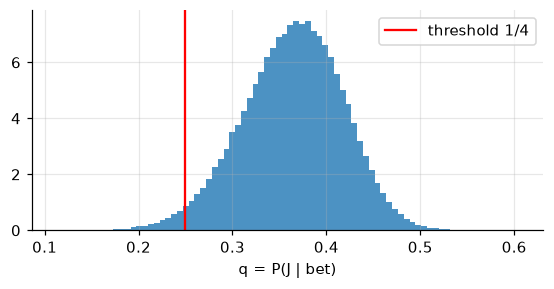

In [34]:
torch.manual_seed(4)
bj = torch.distributions.Beta(11.0, 11.0).sample((200_000,))
bk_ = torch.distributions.Beta(19.0, 3.0).sample((200_000,))
q = bj / (bj + bk_)
margin = 4 * q - 1
print(f"E[q] = {float(q.mean()):.3f}  (threshold 0.25)")
print(f"d* = {'call' if float(margin.mean()) > 0 else 'fold'},  Delta = E[4q - 1] = {float(margin.mean()):.3f} chips")
print(f"pi* = P(q > 1/4) = {float((q > 0.25).double().mean()):.3f}  (simulation sd <= {0.5 / math.sqrt(len(q)):.4f})")
print(f"90% interval for the margin: [{float(torch.quantile(margin, 0.05)):+.3f}, {float(torch.quantile(margin, 0.95)):+.3f}]")
print(f"evidence weight of the bet towards K: w = log(E beta_K / E beta_J) = {math.log((19 / 22) / (11 / 22)):+.3f}")
print("the call is wrong exactly when beta_J / beta_K < 1/3:", f"P = {float((bj / bk_ < 1 / 3).double().mean()):.3f}")

fig, ax = plt.subplots(figsize=(6, 2.6))
ax.hist(q.numpy(), bins=80, density=True, color="tab:blue", alpha=0.8)
ax.axvline(0.25, color="red", label="threshold 1/4")
ax.set_xlabel("q = P(J | bet)")
ax.legend()
plt.show()

### 10.3 Are certificates calibrated?

Many independent scenarios: a true opponent with $\beta_J\sim U(0,0.6)$ and $\beta_K\sim U(0.4,1)$, 40 observed hands with revealed cards, uniform starting PDFs. Each scenario gives a certificate $\pi^\star$ for the call-or-fold decision with Q against a bet, and the true parameters say whether $d^\star$ really was the better action. A calibrated certificate is right at least a fraction $1-\delta$ of the time among decisions certified at level $1-\delta$.

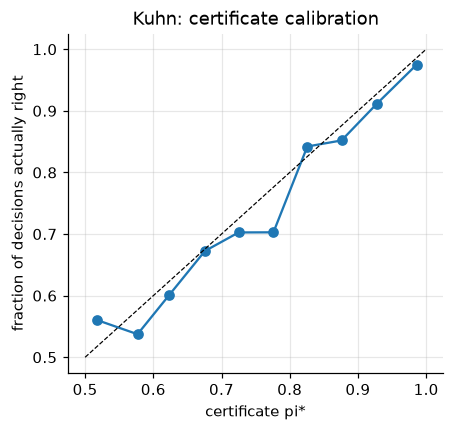

certified at 80%: 2668 decisions, right in 93.4%
certified at 90%: 2051 decisions, right in 96.0%
certified at 95%: 1567 decisions, right in 97.5%


In [35]:
n_sc, n_hands, draws = 4000, 40, 4000
true_bj = torch.rand(n_sc) * 0.6
true_bk = 0.4 + torch.rand(n_sc) * 0.6
cards = torch.randint(0, 3, (n_sc, n_hands))
bets = torch.rand(n_sc, n_hands) < torch.where(cards == 0, true_bj[:, None], true_bk[:, None])
nj, nk = (cards == 0).sum(1), (cards == 2).sum(1)
bj_bets, bk_bets = (bets & (cards == 0)).sum(1), (bets & (cards == 2)).sum(1)
sj = torch.distributions.Beta(1.0 + bj_bets, 1.0 + nj - bj_bets).sample((draws,))
sk = torch.distributions.Beta(1.0 + bk_bets, 1.0 + nk - bk_bets).sample((draws,))
qd = sj / (sj + sk)
call = (4 * qd - 1).mean(0) > 0
pi_star = torch.where(call, (qd > 0.25).double().mean(0), (qd <= 0.25).double().mean(0))
q_true = true_bj / (true_bj + true_bk)
right = call == (q_true > 0.25)

edges = torch.linspace(0.5, 1.0, 11)
idx = torch.bucketize(pi_star, edges[1:-1])
pred = torch.stack([pi_star[idx == i].mean() for i in range(10)])
freq = torch.stack([right[idx == i].double().mean() for i in range(10)])
fig, ax = plt.subplots(figsize=(4.4, 4))
ax.plot(pred, freq, marker="o")
ax.plot([0.5, 1], [0.5, 1], "k--", lw=0.8)
ax.set_xlabel("certificate pi*")
ax.set_ylabel("fraction of decisions actually right")
ax.set_title("Kuhn: certificate calibration")
plt.show()
for delta in (0.2, 0.1, 0.05):
    sel = pi_star >= 1 - delta
    print(f"certified at {1 - delta:.0%}: {int(sel.sum()):4d} decisions, right in {float(right[sel].double().mean()):.1%}")

## 11. E2: Leduc Hold'em

Six cards (J, Q, K in two suits), ante 1, one private card each, one public card after the first round. Bets are 2 in round one and 4 in round two, at most one bet and one raise per round, and player 0 acts first in both rounds. A pair with the public card wins, otherwise the higher card. Here exact best responses and exploitability are cheap, which lets us measure decision value.

### 11.1 The game, CFR and best responses

All computations walk the public tree (betting history and public card) with vectors over the six private cards, so chance is handled exactly. We use:

- **CFR+** with linear averaging for an equilibrium;
- a **best response** against any opponent strategy, where the opponent's private "type" can be a card or a (card, style) pair with prior weights. With style types this is the Bayesian best response to the style-aware model: expected chips by the total expectation theorem at chance and opponent nodes, the maximum at ours;
- the **exact expected value** of two strategies against each other;
- the **exploitability** of a strategy pair: the average of what a best responder wins against each seat, zero exactly at equilibrium.

In [36]:
L_BET = [2, 4]
L_NX, L_K = 24, 4
L_RANK = np.arange(6) // 2


def l_over(h):
    return h.endswith("f") or (len(h) >= 2 and h[-1] == "c")


def l_info(h):
    return len(h) % 2, h.count("r"), h.endswith("r")


def l_legal(h):
    actor, bets, facing = l_info(h)
    return np.array([facing, True, bets < 2])


def l_ctx(rnd, facing, bets, actor):
    return ((rnd * 2 + int(facing)) * 3 + bets) * 2 + actor


def l_bucket(card, pub, rnd):
    if rnd == 0 or pub < 0:
        return L_RANK[card]
    return 3 if L_RANK[card] == L_RANK[pub] else L_RANK[card]


L_LEGAL = torch.tensor([[(x // 6) % 2 == 1, True, (x // 2) % 3 < 2] for x in range(L_NX)])


def l_contrib(h1, h2):
    c = [1, 1]
    for rnd, h in enumerate((h1, h2)):
        bets, level = 0, [0, 0]
        for i, a in enumerate(h):
            p = i % 2
            if a == "r":
                bets += 1
            if a in "rc":
                c[p] += (bets - level[p]) * L_BET[rnd]
                level[p] = bets
    return c


DEAL = (1 - np.eye(6)) / 30


def l_terminal(h1, h2, pub):
    c = l_contrib(h1, h2)
    h = h2 if pub >= 0 else h1
    if h.endswith("f"):
        folder = (len(h) - 1) % 2
        u = np.full((6, 6), -c[0] if folder == 0 else c[1], dtype=float)
        w = DEAL.copy()
    else:
        s = np.array([l_bucket(k, pub, 1) for k in range(6)])
        u = np.sign(s[:, None] - s[None, :]) * c[0]
        w = DEAL.copy()
    if pub >= 0:
        w[pub, :] = 0
        w[:, pub] = 0
        w = w / 4
    return u, w


def l_children(rnd, pub, h1, h2):
    h = h1 if rnd == 0 else h2
    for a in np.nonzero(l_legal(h))[0]:
        yield a, (h1 + ACTIONS[a], h2) if rnd == 0 else (h1, h2 + ACTIONS[a])


def l_state(rnd, pub, h1, h2):
    h = h1 if rnd == 0 else h2
    if h.endswith("f") or (rnd == 1 and l_over(h)):
        return "terminal"
    if rnd == 0 and l_over(h):
        return "chance"
    return "decision"


class LeducCFR:
    def __init__(self):
        self.regret, self.avg = {}, {}

    def current(self, key, legal):
        r = self.regret.get(key, np.zeros((6, 3)))
        pos = np.maximum(r, 0) * legal
        tot = pos.sum(1, keepdims=True)
        return np.where(tot > 0, pos / np.where(tot > 0, tot, 1), legal / legal.sum())

    def average(self, key):
        a = self.avg[key]
        legal = l_legal(key[2] if key[0] == 0 else key[3])
        tot = a.sum(1, keepdims=True)
        return np.where(tot > 0, a / np.where(tot > 0, tot, 1), legal / legal.sum())

    def walk(self, rnd, pub, h1, h2, r0, r1, it):
        kind = l_state(rnd, pub, h1, h2)
        if kind == "terminal":
            u, w = l_terminal(h1, h2, pub)
            return (w * u) @ r1, -(w * u).T @ r0
        if kind == "chance":
            v0, v1 = np.zeros(6), np.zeros(6)
            for p in range(6):
                a, b = self.walk(1, p, h1, "", r0, r1, it)
                v0, v1 = v0 + a, v1 + b
            return v0, v1
        h = h1 if rnd == 0 else h2
        actor = l_info(h)[0]
        legal = l_legal(h)
        key = (rnd, pub, h1, h2)
        sigma = self.current(key, legal)
        va, other = np.zeros((6, 3)), np.zeros(6)
        for a, (n1, n2) in l_children(rnd, pub, h1, h2):
            if actor == 0:
                c0, c1 = self.walk(rnd, pub, n1, n2, r0 * sigma[:, a], r1, it)
                va[:, a], other = c0, other + c1
            else:
                c0, c1 = self.walk(rnd, pub, n1, n2, r0, r1 * sigma[:, a], it)
                va[:, a], other = c1, other + c0
        mine = (sigma * va).sum(1)
        self.regret[key] = np.maximum(self.regret.get(key, 0) + (va - mine[:, None]) * legal, 0)
        reach = r0 if actor == 0 else r1
        self.avg[key] = self.avg.get(key, 0) + it * reach[:, None] * sigma
        return (mine, other) if actor == 0 else (other, mine)

    def solve(self, iters):
        for it in range(1, iters + 1):
            self.walk(0, -1, "", "", np.ones(6), np.ones(6), it)
        return {k: self.average(k) for k in self.avg}


def l_best_response(i, opp, types, prior, rnd=0, pub=-1, h1="", h2="", r=None, policy=None):
    r = np.asarray(prior, dtype=float) if r is None else r
    policy = {} if policy is None else policy
    kind = l_state(rnd, pub, h1, h2)
    if kind == "terminal":
        u, w = l_terminal(h1, h2, pub)
        if i == 1:
            u, w = -u.T, w.T
        return (w[:, types] * u[:, types]) @ r, policy
    if kind == "chance":
        v = np.zeros(6)
        for p in range(6):
            v = v + l_best_response(i, opp, types, prior, 1, p, h1, "", r, policy)[0]
        return v, policy
    h = h1 if rnd == 0 else h2
    actor = l_info(h)[0]
    key = (rnd, pub, h1, h2)
    if actor == i:
        vals = np.full((6, 3), -np.inf)
        for a, (n1, n2) in l_children(rnd, pub, h1, h2):
            vals[:, a] = l_best_response(i, opp, types, prior, rnd, pub, n1, n2, r, policy)[0]
        policy[key] = vals.argmax(1)
        return vals.max(1), policy
    sigma = opp(key)
    v = np.zeros(6)
    for a, (n1, n2) in l_children(rnd, pub, h1, h2):
        v = v + l_best_response(i, opp, types, prior, rnd, pub, n1, n2, r * sigma[:, a], policy)[0]
    return v, policy


def l_value(s0, s1, rnd=0, pub=-1, h1="", h2="", r0=None, r1=None):
    r0 = np.ones(6) if r0 is None else r0
    r1 = np.ones(6) if r1 is None else r1
    kind = l_state(rnd, pub, h1, h2)
    if kind == "terminal":
        u, w = l_terminal(h1, h2, pub)
        return float(r0 @ (w * u) @ r1)
    if kind == "chance":
        return sum(l_value(s0, s1, 1, p, h1, "", r0, r1) for p in range(6))
    h = h1 if rnd == 0 else h2
    actor = l_info(h)[0]
    key = (rnd, pub, h1, h2)
    sigma = (s0 if actor == 0 else s1)(key)
    total = 0.0
    for a, (n1, n2) in l_children(rnd, pub, h1, h2):
        if actor == 0:
            total += l_value(s0, s1, rnd, pub, n1, n2, r0 * sigma[:, a], r1)
        else:
            total += l_value(s0, s1, rnd, pub, n1, n2, r0, r1 * sigma[:, a])
    return total


def table_strategy(table):
    return lambda key: table[key]


def policy_strategy(policy):
    def s(key):
        out = np.zeros((6, 3))
        out[np.arange(6), policy[key]] = 1.0
        return out
    return s


def exploitability(s0, s1):
    br1 = l_best_response(1, s0, np.arange(6), np.ones(6))[0].sum()
    br0 = l_best_response(0, s1, np.arange(6), np.ones(6))[0].sum()
    return (br0 + br1) / 2


t0 = time.time()
cfr = LeducCFR()
for block in range(4):
    for it in range(250 * block + 1, 250 * (block + 1) + 1):
        cfr.walk(0, -1, "", "", np.ones(6), np.ones(6), it)
    EQ = {k: cfr.average(k) for k in cfr.avg}
    eq_s = table_strategy(EQ)
    print(f"CFR+ {250 * (block + 1):4d} iterations: exploitability {exploitability(eq_s, eq_s):.4f} chips/hand "
          f"({time.time() - t0:.0f}s)")
V_EQ = l_value(eq_s, eq_s)
print(f"game value for player 0 at equilibrium: {V_EQ:+.4f}")

CFR+  250 iterations: exploitability 0.0192 chips/hand (2s)


CFR+  500 iterations: exploitability 0.0118 chips/hand (3s)


CFR+  750 iterations: exploitability 0.0085 chips/hand (4s)


CFR+ 1000 iterations: exploitability 0.0070 chips/hand (6s)
game value for player 0 at equilibrium: -0.0853


### 11.2 Opponents in the model's terms

The model describes an opponent by $\theta_{x,s}(a)$, with context $x=$ (round, facing, bets, seat) and bucket $s$ = card rank in round one, rank or "pair" in round two. We project the CFR equilibrium onto this description (averaging its play over all information sets with the same $(x,s)$, weighted by the player's own probability of reaching them) and then add scripted deviations:

- **over-bluffer**: when first to bet, the weakest bucket bets 70% more of its mass;
- **under-folder**: when facing a bet, 70% of the folding mass moves to calling;
- **switching**: alternates between the equilibrium projection and the over-bluffer, with segments of about 300 hands.

In [37]:
def l_key_info(key):
    rnd, pub, h1, h2 = key
    h = h1 if rnd == 0 else h2
    actor, bets, facing = l_info(h)
    return actor, l_ctx(rnd, facing, bets, actor)


THETA_EQ = torch.zeros(L_NX, L_K, 3)
for key, acc in cfr.avg.items():
    actor, x = l_key_info(key)
    for card in range(6):
        if card != key[1]:
            THETA_EQ[x, l_bucket(card, key[1], key[0])] += torch.tensor(acc[card])
THETA_EQ = THETA_EQ + 1e-9 * L_LEGAL[:, None, :]
THETA_EQ = THETA_EQ / THETA_EQ.sum(-1, keepdim=True)


def over_bluffer(theta):
    t = theta.clone()
    for x in range(L_NX):
        rnd, facing = x // 12, (x // 6) % 2
        if not facing:
            t[x, 0] = 0.3 * t[x, 0] + 0.7 * torch.tensor([0.0, 0.0, 1.0])
    return t


def under_folder(theta):
    t = theta.clone()
    for x in range(L_NX):
        if (x // 6) % 2:
            moved = 0.7 * t[x, :, 0]
            t[x, :, 0] -= moved
            t[x, :, 1] += moved
    return t


OPPONENTS = {"equilibrium": THETA_EQ, "over-bluffer": over_bluffer(THETA_EQ), "under-folder": under_folder(THETA_EQ)}


def theta_strategy(theta_by_style, types_style):
    def s(key):
        rnd, pub = key[0], key[1]
        actor, x = l_key_info(key)
        out = np.zeros((len(types_style), 3))
        for j, (card, z) in enumerate(types_style):
            out[j] = theta_by_style[z][x, l_bucket(card, pub, rnd)].numpy()
        return out
    return s


CARD_TYPES = [(c, 0) for c in range(6)]


def model_best_response(thetas, weights):
    types = [(c, z) for z in range(len(thetas)) for c in range(6)]
    card_of = np.array([c for c, z in types])
    prior = np.array([weights[z] for c, z in types])
    opp = theta_strategy(thetas, types)
    v0, p0 = l_best_response(0, opp, card_of, prior)
    v1, p1 = l_best_response(1, opp, card_of, prior)
    return policy_strategy(p0), policy_strategy(p1)


def seat_average(our0, our1, theta):
    opp = theta_strategy([theta], CARD_TYPES)
    return (l_value(our0, opp) - l_value(opp, our1)) / 2


for name, th in OPPONENTS.items():
    b0, b1 = model_best_response([th], [1.0])
    print(f"{name:>13}: equilibrium wins {seat_average(eq_s, eq_s, th):+.3f}, best response to the truth wins "
          f"{seat_average(b0, b1, th):+.3f} chips/hand")

  equilibrium: equilibrium wins +0.077, best response to the truth wins +0.549 chips/hand
 over-bluffer: equilibrium wins +0.083, best response to the truth wins +1.095 chips/hand
 under-folder: equilibrium wins +0.322, best response to the truth wins +1.024 chips/hand


### 11.3 Playing hands and recording them

`l_play` deals and plays one hand between our strategy and an opponent who acts by $\theta$ in the model's terms, and returns a record in the same format as the Hold'em records: the opponent's actions with contexts, our card and the public card as visible cards, and whether the opponent's card was revealed (no fold). The same `Dataset`, `fit` and `filter_predictive` code then runs unchanged.

In [38]:
def l_play(ours, theta, our_seat, gen):
    deck = gen.permutation(6)
    cards, pub = [int(deck[0]), int(deck[1])], int(deck[2])
    h, rnd, acts = ["", ""], 0, []
    while True:
        hh = h[rnd]
        if hh.endswith("f") or (rnd == 1 and l_over(hh)):
            break
        if l_over(hh):
            rnd = 1
            continue
        actor, bets, facing = l_info(hh)
        key = (rnd, pub if rnd else -1, h[0], h[1])
        if actor == our_seat:
            p = ours[our_seat](key)[cards[actor]]
        else:
            x = l_ctx(rnd, facing, bets, actor)
            p = theta[x, l_bucket(cards[actor], pub, rnd)].numpy()
        a = int(gen.choice(3, p=p / p.sum()))
        if actor != our_seat:
            acts.append((rnd, x, a))
        h[rnd] += ACTIONS[a]
    u, w = l_terminal(h[0], h[1], pub if rnd else -1)
    gain = u[cards[0], cards[1]] * (1 if our_seat == 0 else -1)
    opp = 1 - our_seat
    return {"true": cards[opp], "revealed": not h[rnd].endswith("f"), "reached": rnd,
            "vis": [cards[our_seat], pub if rnd else -1], "acts": acts, "gain": gain, "pub": pub}


def l_session(ours, thetas, styles, gen, session=0, offset=0):
    recs = []
    for i, z in enumerate(styles):
        r = l_play(ours, thetas[z], i % 2, gen)
        r.update({"hand": offset + i, "session": session, "style": int(z)})
        recs.append(r)
    return recs


def l_dataset(recs):
    bk = torch.full((len(recs), 2, 6), -1, dtype=torch.long)
    for i, r in enumerate(recs):
        bk[i, 0] = torch.from_numpy(L_RANK)
        bk[i, 1] = torch.tensor([l_bucket(c, r["pub"], 1) for c in range(6)])
        bk[i, 1, r["pub"]] = -1
    return Dataset(bk, torch.eye(6, dtype=torch.bool), [0, 1], recs, L_LEGAL, L_K, split=(1.0, 1.0))


L_REF = THETA_EQ.clone()
EQ_PAIR = (eq_s, eq_s)

### 11.4 Learning curves against static opponents

For each biased opponent, the observer plays the equilibrium for 4000 hands. After $n$ hands we fit the one-style model (with the equilibrium projection as the reference, $\lambda=4$) and the showdown-only estimator, and measure $\sum_a\theta^{\text{true}}\log(\theta^{\text{true}}/\hat\theta)$, weighted by how often each cell is reached.

     opponent |      estimator |      100      250      500     1000     2000     4000
 over-bluffer |             EM |   0.0350   0.0179   0.0123   0.0078   0.0059   0.0041
 over-bluffer |  showdown only |   0.0471   0.0431   0.0620   0.0888   0.1271   0.1719
 under-folder |             EM |   0.1819   0.0403   0.0251   0.0116   0.0079   0.0038
 under-folder |  showdown only |   0.1638   0.0405   0.0419   0.0567   0.0832   0.1064


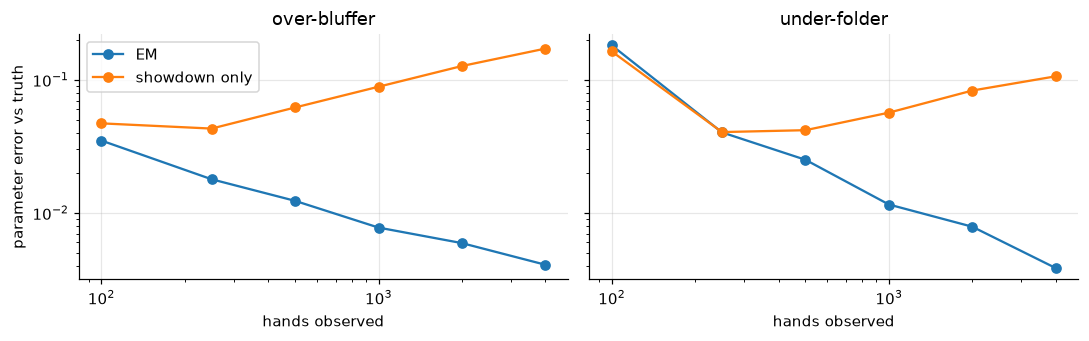

In [39]:
gen = np.random.default_rng(5)
CHECKPOINTS = [100, 250, 500, 1000, 2000, 4000]
CURVES = {}
L_FITS = {}
for name in ("over-bluffer", "under-folder"):
    truth = OPPONENTS[name]
    recs = l_session(EQ_PAIR, [truth], np.zeros(CHECKPOINTS[-1], dtype=int), gen)
    DL = l_dataset(recs)
    reach = counts_from_truth(DL, torch.ones(len(DL), dtype=torch.bool)).sum(-1)
    reach = reach / reach.sum()
    for n in CHECKPOINTS:
        sub = torch.arange(n)
        mask = torch.zeros(len(DL), dtype=torch.bool)
        mask[:n] = True
        em = fit(DL, sub, mz=1, lam=(4.0,), iters=20, ref=L_REF, verbose=False)
        sd = posterior_mean(counts_from_truth(DL, mask & DL.revealed), 4.0 * L_REF)
        for est, th in (("EM", em["theta"][0]), ("showdown only", sd)):
            kl = (truth * (safe_log(truth) - safe_log(th)) * L_LEGAL[:, None, :]).sum(-1)
            CURVES[name, est, n] = float((kl * reach).sum())
        if n == CHECKPOINTS[-1]:
            L_FITS[name] = {"EM": em["theta"][0], "showdown only": sd}

print(f"{'opponent':>13} | {'estimator':>14} | " + " ".join(f"{n:>8}" for n in CHECKPOINTS))
for name in ("over-bluffer", "under-folder"):
    for est in ("EM", "showdown only"):
        print(f"{name:>13} | {est:>14} | " + " ".join(f"{CURVES[name, est, n]:8.4f}" for n in CHECKPOINTS))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2), sharey=True)
for ax, name in zip(axes, ("over-bluffer", "under-folder")):
    for est in ("EM", "showdown only"):
        ax.plot(CHECKPOINTS, [CURVES[name, est, n] for n in CHECKPOINTS], marker="o", label=est)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel("hands observed")
    ax.set_title(name)
axes[0].set_ylabel("parameter error vs truth")
axes[0].legend()
plt.tight_layout()
plt.show()

### 11.5 Decision value against static opponents

Exact expected chips per hand (averaged over both seats) for four strategies of ours, and the exploitability of each: how much a best responder would win against it, the safety cost of exploiting.

In [40]:
print(f"{'opponent':>13} | {'our strategy':>28} | {'chips/hand':>10} | {'exploitability':>14}")
DECISION_VALUE = {}
for name in ("over-bluffer", "under-folder"):
    truth = OPPONENTS[name]
    rows = [("equilibrium", EQ_PAIR),
            ("best response to EM model", model_best_response([L_FITS[name]["EM"]], [1.0])),
            ("best response to showdown-only", model_best_response([L_FITS[name]["showdown only"]], [1.0])),
            ("best response to the truth", model_best_response([truth], [1.0]))]
    for label, (s0, s1) in rows:
        v = seat_average(s0, s1, truth)
        DECISION_VALUE[name, label] = v
        print(f"{name:>13} | {label:>28} | {v:+10.3f} | {exploitability(s0, s1):14.3f}")

     opponent |                 our strategy | chips/hand | exploitability
 over-bluffer |                  equilibrium |     +0.083 |          0.007
 over-bluffer |    best response to EM model |     +1.047 |          3.233
 over-bluffer | best response to showdown-only |     +0.698 |          2.483
 over-bluffer |   best response to the truth |     +1.095 |          3.733
 under-folder |                  equilibrium |     +0.322 |          0.007
 under-folder |    best response to EM model |     +1.016 |          2.733
 under-folder | best response to showdown-only |     +0.946 |          2.667
 under-folder |   best response to the truth |     +1.024 |          2.983


### 11.6 A switching opponent: style detection

The opponent alternates between the equilibrium projection (style 1) and the over-bluffer (style 2). We fit the two-style model on a 6000-hand training session, then run the forward recursion on new sessions and raise an alarm when $P(Z_h=2\mid\text{hands so far})$ crosses $\tau=0.9$.

The baseline is a sliding-window frequency: the opponent's betting rate when first to act in round one over the last 60 hands, with an alarm when it exceeds its mean plus 2.5 standard deviations under style 1 (calibrated on the training session, where the switch points are known).

training: eps = 0.0038 (true switch rate 0.0042), most probable style matches the truth on 97.4% of hands
P(bet | first to act, round 1, J): learned [0.067 0.7  ]  true [0.082 0.725]


    style model: median detection delay    26 hands, mean  28.1; false alarms 2.12 per 1000 style-1 hands
 sliding window: median detection delay    52 hands, mean  57.3; false alarms 2.41 per 1000 style-1 hands


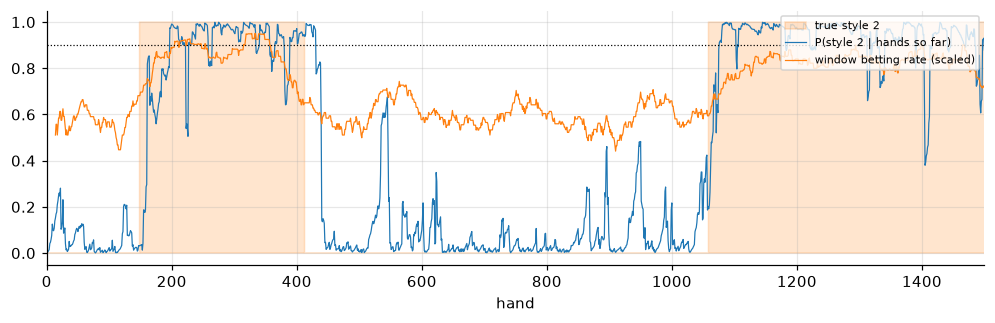

In [41]:
def switching_styles(n, gen, mean_len=300):
    styles, z = [], 0
    while len(styles) < n:
        styles += [z] * int(gen.geometric(1 / mean_len))
        z = 1 - z
    return np.array(styles[:n])


SWITCH_THETAS = [OPPONENTS["equilibrium"], OPPONENTS["over-bluffer"]]
gen = np.random.default_rng(6)
train_styles = switching_styles(6000, gen)
train_recs = l_session(EQ_PAIR, SWITCH_THETAS, train_styles, gen)
DS = l_dataset(train_recs)
EM_SW = fit(DS, torch.arange(len(DS)), mz=2, lam=(200.0, 4.0), iters=25, ref=L_REF, verbose=False)
EM_SW1 = fit(DS, torch.arange(len(DS)), mz=1, lam=(4.0,), iters=20, ref=L_REF, verbose=False)
agree = (EM_SW["gamma"].argmax(1).numpy() == train_styles).mean()
print(f"training: eps = {EM_SW['eps']:.4f} (true switch rate {np.mean(train_styles[1:] != train_styles[:-1]):.4f}), "
      f"most probable style matches the truth on {agree:.1%} of hands")
x_open = l_ctx(0, False, 0, 0)
print("P(bet | first to act, round 1, J): learned", np.round([float(EM_SW["theta"][z, x_open, 0, 2]) for z in range(2)], 3),
      " true", np.round([float(SWITCH_THETAS[z][x_open, 0, 2]) for z in range(2)], 3))


def open_bets(recs):
    out = np.full(len(recs), np.nan)
    for i, r in enumerate(recs):
        x_open = l_ctx(0, False, 0, 1 - i % 2)
        acts = [a for t, x, a in r["acts"] if x == x_open]
        if acts:
            out[i] = float(acts[0] == 2)
    return out


def window_rate(v, w=60):
    out = np.full(len(v), np.nan)
    for i in range(len(v)):
        seg = v[max(0, i - w + 1):i + 1]
        seg = seg[~np.isnan(seg)]
        if len(seg) >= 10:
            out[i] = seg.mean()
    return out


rate_train = window_rate(open_bets(train_recs))
base = rate_train[(train_styles == 0) & ~np.isnan(rate_train)]
WINDOW_THRESHOLD = base.mean() + 2.5 * base.std()


def alarms(signal, styles, threshold):
    on = np.nan_to_num(signal, nan=0.0) > threshold
    starts = np.nonzero(on & ~np.r_[False, on[:-1]])[0]
    delays, false = [], 0
    switch_in = np.nonzero((styles == 1) & np.r_[True, styles[:-1] == 0])[0]
    for s in switch_in:
        end = s
        while end < len(styles) and styles[end] == 1:
            end += 1
        hit = np.nonzero(on[s:end])[0]
        delays.append(hit[0] if len(hit) else end - s)
    false = sum(1 for s in starts if styles[s] == 0)
    return np.array(delays), false / max(1, (styles == 0).sum()) * 1000


det = {"style model": ([], []), "sliding window": ([], [])}
TEST_SESSIONS = []
for k in range(5):
    styles = switching_styles(3000, gen)
    recs = l_session(EQ_PAIR, SWITCH_THETAS, styles, gen, session=0)
    DT = l_dataset(recs)
    loge, _ = e_step(DT, safe_log(EM_SW["theta"]), torch.arange(len(DT)))
    pred, filt = filter_predictive(loge, session_grid(DT, torch.arange(len(DT))), torch.log(EM_SW["rho"]),
                                   torch.log(transition(EM_SW["eps"], 2)))
    p2 = np.exp(filt[:, 1].numpy())
    wr = window_rate(open_bets(recs))
    for name, sig, thr in (("style model", p2, 0.9), ("sliding window", wr, WINDOW_THRESHOLD)):
        d, f = alarms(sig, styles, thr)
        det[name][0].extend(d)
        det[name][1].append(f)
    TEST_SESSIONS.append((styles, p2, wr, np.exp(pred[:, 1].numpy())))
for name, (d, f) in det.items():
    print(f"{name:>15}: median detection delay {np.median(d):5.0f} hands, mean {np.mean(d):5.1f}; "
          f"false alarms {np.mean(f):.2f} per 1000 style-1 hands")

styles, p2, wr, _ = TEST_SESSIONS[0]
fig, ax = plt.subplots(figsize=(11, 3))
ax.fill_between(np.arange(len(styles)), 0, styles, step="mid", color="tab:orange", alpha=0.2, label="true style 2")
ax.plot(p2, lw=0.8, label="P(style 2 | hands so far)")
ax.plot(wr / max(np.nanmax(wr), 1e-9), lw=0.8, label="window betting rate (scaled)")
ax.axhline(0.9, color="k", ls=":", lw=0.8)
ax.set_xlabel("hand")
ax.set_xlim(0, 1500)
ax.legend(fontsize=7, loc="upper right")
plt.show()

### 11.7 Decision value against the switching opponent

Simulated chips per hand over the five test sessions (mean $\pm$ 2 standard deviations of the mean) for: the equilibrium; the best response to the one-style model fitted on the switching training data; and the **style-aware** best response, recomputed before each hand against the two-style model with the current style PMF (the PMF is rounded to a 0.05 grid so each policy is computed once).

In [42]:
GRID = np.round(np.linspace(0, 1, 21), 2)
AWARE = {p: model_best_response([EM_SW["theta"][0], EM_SW["theta"][1]], [1 - p, p]) for p in GRID}
STATIC = model_best_response([EM_SW1["theta"][0]], [1.0])

results = {"equilibrium": [], "best response, one style": [], "style-aware best response": []}
gen = np.random.default_rng(7)
for styles, _, _, pred2 in TEST_SESSIONS:
    for label in results:
        gains = []
        for i, z in enumerate(styles):
            if label == "equilibrium":
                ours = EQ_PAIR
            elif label == "best response, one style":
                ours = STATIC
            else:
                ours = AWARE[GRID[np.abs(GRID - pred2[i]).argmin()]]
            gains.append(l_play(ours, SWITCH_THETAS[z], i % 2, gen)["gain"])
        results[label].append(np.mean(gains))
for label, v in results.items():
    v = np.array(v)
    print(f"{label:>26}: {v.mean():+.3f} ± {2 * v.std(ddof=1) / math.sqrt(len(v)):.3f} chips/hand")
print(f"\nexploitability of the style-aware policy: {exploitability(*AWARE[0.0]):.3f} (style-1 belief), "
      f"{exploitability(*AWARE[1.0]):.3f} (style-2 belief); equilibrium {exploitability(*EQ_PAIR):.3f}")

               equilibrium: +0.096 ± 0.103 chips/hand
  best response, one style: +0.630 ± 0.110 chips/hand
 style-aware best response: +0.726 ± 0.125 chips/hand

exploitability of the style-aware policy: 4.433 (style-1 belief), 3.650 (style-2 belief); equilibrium 0.007


## 12. Human play: heads-up hands from the IRC Poker Database

ACPC bots never change style within a match, so the style chain has nothing to find there. Humans might. The IRC Poker Database (University of Alberta, 1995–2001) records real-money-free but serious limit Hold'em played by people on IRC servers; we use the heads-up hands of the `#holdem` channel (`devbox run data-irc` downloads it, about 1 GB).

Three facts about this data matter for the model:

- **The action order is not stored**, only each player's action string per street. With two players the order is forced: the small blind (position 1) acts first on every street, and players alternate. We rebuild every hand that way and keep it only if it is a legal limit betting sequence (and drop hands where someone quits, is kicked or goes all-in).
- **The IRC server showed both hands at every showdown.** Cards are hidden exactly when someone folds, so, as in ACPC, whether cards are seen is a function of the betting and Proposition 1 applies. (Online sites where losers may muck would need the extra conditional PMF of the remark after Proposition 1.)
- **There is no ground truth for folded hands**, so here we evaluate on what is observable: the predictive probability of held-out hands.

### 12.1 Reading and rebuilding the hands

In [43]:
import io
import tarfile

IRC_ARCHIVE = DATA / "irc" / "IRCdata.tgz"
IRC_MONTHS = [f"holdem.{y}{m:02d}" for y in (1998, 1999) for m in range(1, 13)]
SESSION_GAP = 1800


def irc_actions(raw):
    return "" if raw == "-" else raw.replace("B", "")


def irc_rebuild(row1, row2, board_cards):
    if any(ch in "QKA" for row in (row1, row2) for s in row[4:8] for ch in s):
        return None
    hole = {seat: parse_cards("".join(row[11:13])) if len(row) >= 13 else None for seat, row in ((1, row1), (2, row2))}
    events, pot, folded = [], 15.0, False
    for street in range(4):
        s = {1: irc_actions(row1[4 + street]), 2: irc_actions(row2[4 + street])}
        if not s[1] and not s[2]:
            break
        if folded:
            return None
        if street > 0:
            events.append(("deal", street, 0, -1, -1, pot, 0.0))
        bets, level = (1, {1: 0.5, 2: 1.0}) if street == 0 else (0, {1: 0.0, 2: 0.0})
        pos, actor, acted = {1: 0, 2: 0}, 1, 0
        while True:
            if pos[actor] >= len(s[actor]):
                break
            ch = s[actor][pos[actor]]
            pos[actor] += 1
            facing = level[actor] < bets
            if ch == "f":
                act = 0
            elif ch in "kc":
                act = 1
                if ch == "k" and facing:
                    return None
            elif ch in "br":
                act = 2
                if bets >= 4:
                    return None
            else:
                return None
            to_call = (bets - level[actor]) * BET[street]
            events.append(("act", street, actor, act, context(street, int(facing), bets, int(actor == 2)), pot, to_call))
            acted += 1
            if act == 0:
                folded = True
                break
            if act == 1:
                pot, level[actor] = pot + to_call, bets
                if acted >= 2 and level[1] == level[2]:
                    break
            else:
                bets += 1
                pot, level[actor] = pot + (bets - level[actor]) * BET[street], bets
            actor = 3 - actor
        if pos[1] != len(s[1]) or pos[2] != len(s[2]):
            return None
    reached = max(e[1] for e in events)
    n_board = [0, 3, 4, 5][reached]
    if len(board_cards) < n_board:
        return None
    if not folded and (hole[1] is None or hole[2] is None):
        return None
    return {"hole": hole, "board": board_cards[:n_board], "events": events, "revealed": not folded}


TRUNCATED = []


def read_irc(months):
    hands = []
    with tarfile.open(IRC_ARCHIVE, "r:gz") as outer:
        for member in outer:
            month = member.name.split("/")[-1].removesuffix(".tgz")
            if month not in months:
                continue
            inner = tarfile.open(fileobj=io.BytesIO(outer.extractfile(member).read()), mode="r:gz")
            hdb, rows, files = {}, {}, []
            try:
                for m in inner:
                    if m.isfile():
                        files.append((m.name, inner.extractfile(m).read()))
            except (EOFError, tarfile.ReadError):
                TRUNCATED.append(month)
            for name, data in files:
                text = data.decode("latin-1").splitlines()
                if name.endswith("/hdb"):
                    for line in text:
                        f = line.split()
                        if len(f) > 3 and f[3] == "2":
                            hdb[f[0]] = f
                elif "/pdb/pdb." in name:
                    for line in text:
                        f = line.split()
                        if len(f) >= 11 and f[2] == "2":
                            rows.setdefault(f[1], []).append(f)
            for stamp, f in hdb.items():
                r = rows.get(stamp, [])
                if len(r) != 2 or {x[3] for x in r} != {"1", "2"}:
                    continue
                r1, r2 = sorted(r, key=lambda x: x[3])
                try:
                    hand = irc_rebuild(r1, r2, parse_cards("".join(f[8:13])))
                except ValueError:
                    hand = None
                if hand is None:
                    continue
                hand.update({"time": int(stamp), "month": month, "players": [r1[0], r2[0]],
                             "net": {1: float(r1[10]) - float(r1[9]), 2: float(r2[10]) - float(r2[9])}})
                hands.append(hand)
    hands.sort(key=lambda h: h["time"])
    return hands


irc_cache = CACHE / f"irc_{IRC_MONTHS[0]}_{IRC_MONTHS[-1]}.pt"
if irc_cache.exists():
    IRC_HANDS = torch.load(irc_cache, weights_only=False)
else:
    assert IRC_ARCHIVE.exists(), "No IRC data: run `devbox run data irc` first."
    t0 = time.time()
    IRC_HANDS = read_irc(set(IRC_MONTHS))
    torch.save(IRC_HANDS, irc_cache)
    print(f"parsed in {time.time() - t0:.0f}s; truncated monthly archives (read up to the damage): {TRUNCATED or 'none'}")
irc_shown = np.mean([h["revealed"] for h in IRC_HANDS])
print(f"{len(IRC_HANDS):,} heads-up hands from {len(IRC_MONTHS)} months; {irc_shown:.1%} reach showdown; "
      f"{len({p for h in IRC_HANDS for p in h['players']}):,} players")

87,428 heads-up hands from 24 months; 22.1% reach showdown; 2,714 players


### 12.2 Records and sessions

A session is one player's run of heads-up hands against the same opponent with no gap longer than 30 minutes. As for ACPC, each hand gives two records (each player in turn is the opponent), the bucket table gives the strength buckets, and each session is split in time 60/10/30. The observer's own cards are unknown here unless shown, so card removal uses the board only.

In [44]:
def irc_records(hands, min_session=40):
    by_pair, records, sessions = {}, [], {}
    for i, h in enumerate(hands):
        by_pair.setdefault(tuple(sorted(h["players"])), []).append(i)
    for pair, idx in by_pair.items():
        runs, cur = [], [idx[0]]
        for a, b in zip(idx, idx[1:]):
            if hands[b]["time"] - hands[a]["time"] > SESSION_GAP:
                runs.append(cur)
                cur = []
            cur.append(b)
        runs.append(cur)
        for run in runs:
            if len(run) < min_session:
                continue
            for name in pair:
                sid = len(sessions)
                sessions[sid] = (name, pair)
                for i in run:
                    h = hands[i]
                    opp = h["players"].index(name) + 1
                    board = h["board"] + [-1] * (5 - len(h["board"]))
                    true = int(COMBO_ID[h["hole"][opp][0], h["hole"][opp][1]]) if h["revealed"] else 0
                    records.append({"hand": i, "session": sid, "opp": opp, "name": name, "true": true,
                                    "revealed": h["revealed"], "reached": max(0, len(h["board"]) - 2),
                                    "vis": board, "acts": [(e[1], e[4], e[3]) for e in h["events"] if e[0] == "act" and e[2] == opp],
                                    "net_before": None})
    return records, sessions


IRC_REC, IRC_SESSIONS = irc_records(IRC_HANDS)
prev_net = {}
for r in IRC_REC:
    key = r["session"]
    r["net_before"] = prev_net.get(key)
    prev_net[key] = IRC_HANDS[r["hand"]]["net"][r["opp"]]
BK_IRC = BoardBuckets(IRC_HANDS, BOARD_TABLES)
DI = Dataset(BK_IRC, COMBO_HAS_T, [1, 1, 1, 2, 3], IRC_REC, LEGAL, K)
sizes = torch.bincount(DI.session).double()
print(f"{len(DI):,} records in {len(IRC_SESSIONS):,} sessions (median {sizes.median():.0f} hands, "
      f"max {sizes.max():.0f}); {int(DI.train.sum()):,} train / {int(DI.val.sum()):,} validation / {int(DI.test.sum()):,} test")

96,008 records in 1,072 sessions (median 63 hands, max 1541); 58,008 train / 9,676 validation / 28,324 test


### 12.3 Do humans change style within a session?

We fit models with $M=1,2,3$ styles on the training hands, with the same prior as for ACPC, and compare their predictive probability of the **test** hands: the style PMF before each hand comes from the forward recursion over all earlier hands of the session. If people kept one style per session, extra styles could still separate players but the learned switching probability $\varepsilon$ would collapse to zero, as it did for the bots.

In [45]:
def predictive_score(Dx, model, recs_all, score_mask):
    loge, _ = e_step(Dx, safe_log(model["theta"]), recs_all)
    if model["M"] == 1:
        return float(loge[score_mask].sum())
    pred, _ = filter_predictive(loge, session_grid(Dx, recs_all), torch.log(model["rho"]),
                                torch.log(transition(model["eps"], model["M"])))
    return float(torch.logsumexp(pred + loge, -1)[score_mask].sum())


IRC_REF = context_reference(DI, DI.train)
IRC_TRAIN = torch.nonzero(DI.train).squeeze(1)
IRC_ALL = torch.arange(len(DI))
IRC_MODELS = {}
t0 = time.time()
for mz in (1, 2, 3):
    init = IRC_MODELS[1]["theta"][0] if mz > 1 else None
    IRC_MODELS[mz] = memo(f"irc_M{mz}", lambda: fit(DI, IRC_TRAIN, mz=mz, lam=(LAM, 2.0), ref=IRC_REF, init=init, verbose=False))
    score = predictive_score(DI, IRC_MODELS[mz], IRC_ALL, DI.test)
    IRC_MODELS[mz]["test_score"] = score
    eps = f"{IRC_MODELS[mz]['eps']:.4f}" if mz > 1 else "-"
    print(f"M={mz}: test log P = {score:,.1f}   eps = {eps}   ({time.time() - t0:.0f}s)")
print(f"for comparison, the ACPC bots under the same model: eps = {EMS['eps']:.4f}")
n_test = int(DI.test.sum())
for mz in (2, 3):
    gain = (IRC_MODELS[mz]["test_score"] - IRC_MODELS[1]["test_score"]) / n_test
    print(f"M={mz} vs M=1: {gain:+.4f} log-probability per test hand")

M=1: test log P = -87,434.8   eps = -   (2s)


M=2: test log P = -84,607.5   eps = 0.0197   (4s)


M=3: test log P = -82,877.9   eps = 0.0155   (6s)
for comparison, the ACPC bots under the same model: eps = 0.0014
M=2 vs M=1: +0.0998 log-probability per test hand
M=3 vs M=1: +0.1609 log-probability per test hand


### 12.4 Tilt: does a big loss change the style?

With the best style model we compute, for every hand, the probability that the style changed since the previous hand, $P(Z_h\neq Z_{h-1}\mid\text{all hands of the session})$, from the forward and backward recursions. If tilt is real, this probability should be higher right after the player lost a big pot than after other hands. "Big" means losing at least 100 chips (five big bets) in the previous hand; the comparison is made within the same sessions, with intervals of $\pm2$ standard deviations of the mean over sessions.

In [46]:
def switch_probs(loge, grid, model):
    log_g = torch.log(transition(model["eps"], model["M"]))
    S, L = grid.shape
    real = grid >= 0
    le = torch.where(real[..., None], loge[grid.clamp(min=0)], torch.zeros(()))
    la = torch.empty(S, L, model["M"])
    la[:, 0] = torch.log(model["rho"]) + le[:, 0]
    for t in range(1, L):
        la[:, t] = le[:, t] + torch.logsumexp(la[:, t - 1, :, None] + log_g, 1)
    lb = torch.zeros(S, L, model["M"])
    for t in range(L - 2, -1, -1):
        lb[:, t] = torch.logsumexp(log_g + (le[:, t + 1] + lb[:, t + 1])[:, None, :], 2)
    logz = torch.logsumexp(la[:, -1], -1)
    xi = torch.exp(la[:, :-1, :, None] + log_g + (le[:, 1:] + lb[:, 1:])[:, :, None, :] - logz[:, None, None, None])
    stay = xi.diagonal(dim1=-2, dim2=-1).sum(-1)
    out = torch.full((len(loge),), float("nan"))
    rows = grid[:, 1:][real[:, 1:]]
    out[rows] = (1 - stay)[real[:, 1:]]
    return out


BEST_IRC = max(IRC_MODELS, key=lambda m: IRC_MODELS[m]["test_score"])
if BEST_IRC == 1:
    print("The one-style model predicts held-out human hands best: no evidence of style changes to analyse.")
else:
    model = IRC_MODELS[BEST_IRC]
    loge_irc, _ = e_step(DI, safe_log(model["theta"]), IRC_ALL)
    SWITCH = switch_probs(loge_irc, session_grid(DI, IRC_ALL), model)
    before = torch.tensor([np.nan if r["net_before"] is None else r["net_before"] for r in IRC_REC])
    groups = {"after losing >= 100": before <= -100, "after a smaller loss": (before < 0) & (before > -100),
              "after breaking even or winning": before >= 0}
    print(f"style model with M={BEST_IRC}: P(style changed since the previous hand)")
    sess = DI.session
    for name, m in groups.items():
        ok = m & ~torch.isnan(SWITCH)
        mean, se = session_mean(SWITCH[ok], sess[ok])
        print(f"{name:>32}: {mean:.4f} ± {se:.4f}   ({int(ok.sum()):,} hands)")
    big, rest = groups["after losing >= 100"], groups["after breaking even or winning"] | groups["after a smaller loss"]
    diffs = []
    for s in torch.unique(sess).tolist():
        a = SWITCH[(sess == s) & big & ~torch.isnan(SWITCH)]
        b = SWITCH[(sess == s) & rest & ~torch.isnan(SWITCH)]
        if len(a) and len(b):
            diffs.append(float(a.mean() - b.mean()))
    diffs = np.array(diffs)
    print(f"\nwithin-session difference (big loss minus other hands): {diffs.mean():+.4f} ± {2 * diffs.std(ddof=1) / math.sqrt(len(diffs)):.4f} "
          f"over {len(diffs)} sessions")
    share = [float(model["counts"][z][..., 2].sum() / model["counts"][z].sum()) for z in range(BEST_IRC)]
    print("share of bets and raises among each style's actions:", np.round(share, 3))

style model with M=3: P(style changed since the previous hand)
             after losing >= 100: 0.0270 ± 0.0048   (1,221 hands)
            after a smaller loss: 0.0190 ± 0.0013   (45,841 hands)
  after breaking even or winning: 0.0181 ± 0.0010   (47,874 hands)



within-session difference (big loss minus other hands): +0.0048 ± 0.0046 over 485 sessions
share of bets and raises among each style's actions: [0.312 0.637 0.23 ]
